# Capstone Project: Analysing Insurance Claims for SafeDrive Insurance Ltd.

## Stage 1: Business Understanding, Data Preparation, EDA and Feature Engineering

This notebook covers the first stage of the capstone project. The objective is to understand the business problem, inspect and clean the dataset, perform exploratory data analysis, create business-relevant features, and prepare a clean dataset for modelling.

In [2]:
import pandas as pd

df = pd.read_csv("dataset.csv")
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


## 1. Business Problem Understanding

SafeDrive Insurance Ltd. is facing increasing claim payouts. In the insurance business, the company earns revenue through premiums collected from policyholders and pays money when claims are filed.

If claim frequency increases, the company faces higher financial risk. Therefore, SafeDrive wants to identify policyholders who are more likely to file a claim during the policy period.

The goal of this project is to build a predictive analytics solution that can flag high-risk policyholders early and help business teams take preventive action.

## 2. Analytical Objective

The analytical objective is to build a binary classification model that predicts whether a policyholder is likely to file an insurance claim or not.

The target variable is `is_claim`, where:

- `0` means No Claim
- `1` means Claim Filed

The model will use policyholder information, policy details, vehicle information, and vehicle safety features to predict claim risk.

## 3. Expected Business Outcome

The expected business outcome is to help SafeDrive Insurance:

- Identify high-risk policyholders early
- Improve underwriting decisions
- Support better premium pricing
- Reduce claim-related financial losses
- Understand the key factors driving claim risk

## 4. Target Audience

The target audience for this analysis includes:

- Underwriting team
- Risk management team
- Pricing team
- Claims management team
- Senior business management

These teams can use the model output and insights to make better business decisions.

## 5. Business Questions

This analysis aims to answer the following business questions:

1. Which policyholder, vehicle, and safety-related features are associated with higher claim risk?
2. Does vehicle age influence the likelihood of filing a claim?
3. Do vehicle safety features such as airbags, NCAP rating, ESC, brake assist, and speed alert affect claim probability?
4. Are certain vehicle segments, fuel types, or area clusters associated with higher claim rates?
5. Can policyholders be segmented into Low, Medium, and High risk groups based on predicted claim probability?

## 6. Business Success Metrics

The success of this project from a business perspective will be evaluated using the following metrics:

1. Identification of high-risk policyholders  
   The model should help the business identify customers who are more likely to file a claim.

2. Better risk segmentation  
   Policyholders should be grouped into Low, Medium, and High risk categories based on claim probability.

3. Actionable business insights  
   The analysis should identify important claim-risk drivers that can support underwriting, pricing, and risk management decisions.

## 7. Model Evaluation Metrics

Since this is a binary classification problem, the model will be evaluated using:

1. Accuracy  
   Measures the overall percentage of correct predictions. However, accuracy alone may not be reliable because the dataset is imbalanced.

2. Precision  
   Measures how many predicted claim cases are actually claim cases. This helps avoid wrongly flagging too many low-risk customers as high risk.

3. Recall  
   Measures how many actual claim cases the model is able to identify. This is important because missing high-risk customers can create financial risk.

4. F1 Score  
   Balances precision and recall, especially useful for imbalanced datasets.

5. ROC-AUC  
   Measures how well the model separates claim and no-claim policyholders across different thresholds.

## 8. Import Required Libraries

In this step, the required Python libraries are imported for data handling, numerical operations, visualization, and warning control.

In [3]:
# Importing required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 9. Load the Dataset

The dataset is loaded using Pandas. After loading the data, the first few rows are displayed to confirm that the file has been imported correctly.

In [4]:
# Loading the dataset

df = pd.read_csv("dataset.csv")

# Displaying first 5 rows
df.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


### Observation

The dataset has been loaded successfully. The first few rows show policy ID, policy tenure, policyholder age, vehicle details, safety features, and the target variable `is_claim`.

## 10. Dataset Shape

The shape of the dataset is checked to understand the number of rows and columns available for analysis.

In [5]:
# Checking number of rows and columns

df.shape

(58592, 44)

### Observation

The dataset contains 58,592 rows and 44 columns. Each row represents one policy record.

## 11. Column Names

In this step, all column names are displayed to understand the variables available in the dataset. This helps identify policy-related, policyholder-related, vehicle-related, safety-related, and target columns.

In [6]:
# Displaying all column names

df.columns

Index(['policy_id', 'policy_tenure', 'age_of_car', 'age_of_policyholder',
       'area_cluster', 'population_density', 'make', 'segment', 'model',
       'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags',
       'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors',
       'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder',
       'transmission_type', 'gear_box', 'steering_type', 'turning_radius',
       'length', 'width', 'height', 'gross_weight', 'is_front_fog_lights',
       'is_rear_window_wiper', 'is_rear_window_washer',
       'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks',
       'is_central_locking', 'is_power_steering',
       'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror',
       'is_ecw', 'is_speed_alert', 'ncap_rating', 'is_claim'],
      dtype='object')

### Observation

The dataset contains policy information, policyholder information, vehicle details, vehicle safety features, and the target variable `is_claim`. The target variable will be used for claim prediction.

## 12. Data Types and Schema

The data types of all columns are checked to understand which variables are numerical and which are categorical. This is important because numerical and categorical variables require different preprocessing steps before modelling.

In [7]:
# Checking dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58592 entries, 0 to 58591
Data columns (total 44 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   policy_id                         58592 non-null  object 
 1   policy_tenure                     58592 non-null  float64
 2   age_of_car                        58592 non-null  float64
 3   age_of_policyholder               58592 non-null  float64
 4   area_cluster                      58592 non-null  object 
 5   population_density                58592 non-null  int64  
 6   make                              58592 non-null  int64  
 7   segment                           58592 non-null  object 
 8   model                             58592 non-null  object 
 9   fuel_type                         58592 non-null  object 
 10  max_torque                        58592 non-null  object 
 11  max_power                         58592 non-null  object 
 12  engi

In [8]:
# Checking data types separately

df.dtypes

policy_id                            object
policy_tenure                       float64
age_of_car                          float64
age_of_policyholder                 float64
area_cluster                         object
population_density                    int64
make                                  int64
segment                              object
model                                object
fuel_type                            object
max_torque                           object
max_power                            object
engine_type                          object
airbags                               int64
is_esc                               object
is_adjustable_steering               object
is_tpms                              object
is_parking_sensors                   object
is_parking_camera                    object
rear_brakes_type                     object
displacement                          int64
cylinder                              int64
transmission_type               

### Observation

The dataset contains a combination of numerical and categorical variables. Numerical variables include policy tenure, age of car, age of policyholder, population density, engine-related features, vehicle dimensions, and NCAP rating. Categorical variables include area cluster, segment, model, fuel type, engine type, transmission type, steering type, rear brakes type, and safety feature indicators.

In [9]:
# Summary statistics for numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
policy_tenure,58592.0,0.611246,0.414156,0.002735,0.210250,0.573792,1.039104,1.396641
age_of_car,58592.0,0.069424,0.056721,0.000000,0.020000,0.060000,0.110000,1.000000
age_of_policyholder,58592.0,0.469420,0.122886,0.288462,0.365385,0.451923,0.548077,1.000000
population_density,58592.0,18826.858667,17660.174792,290.000000,6112.000000,8794.000000,27003.000000,73430.000000
make,58592.0,1.763722,1.136988,1.000000,1.000000,1.000000,3.000000,5.000000
airbags,58592.0,3.137066,1.832641,1.000000,2.000000,2.000000,6.000000,6.000000
displacement,58592.0,1162.355851,266.304786,796.000000,796.000000,1197.000000,1493.000000,1498.000000
cylinder,58592.0,3.626963,0.483616,3.000000,3.000000,4.000000,4.000000,4.000000
gear_box,58592.0,5.245443,0.430353,5.000000,5.000000,5.000000,5.000000,6.000000
turning_radius,58592.0,4.852893,0.228061,4.500000,4.600000,4.800000,5.000000,5.200000


### Observation

The summary statistics provide an overview of numerical columns such as mean, standard deviation, minimum, maximum, and quartile values. These statistics will help during outlier detection, skewness analysis, and feature engineering.

## 14. Missing Values Check

Missing values are checked because incomplete data can affect analysis and model performance. If missing values are found, numerical columns can be imputed using mean or median, while categorical columns can be imputed using mode.

In [10]:
# Checking missing values column-wise

missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

policy_id                           0
policy_tenure                       0
steering_type                       0
turning_radius                      0
length                              0
width                               0
height                              0
gross_weight                        0
is_front_fog_lights                 0
is_rear_window_wiper                0
is_rear_window_washer               0
is_rear_window_defogger             0
is_brake_assist                     0
is_power_door_locks                 0
is_central_locking                  0
is_power_steering                   0
is_driver_seat_height_adjustable    0
is_day_night_rear_view_mirror       0
is_ecw                              0
is_speed_alert                      0
ncap_rating                         0
gear_box                            0
transmission_type                   0
cylinder                            0
max_torque                          0
age_of_car                          0
age_of_polic

In [11]:
# Checking total missing values in the dataset

df.isnull().sum().sum()

np.int64(0)

### Observation

There are no missing values in the dataset. Therefore, missing value imputation is not required.

## 15. Duplicate Records Check

Duplicate records are checked because repeated rows can create bias in analysis and model training. If duplicate rows are present, they should be removed before modelling.

In [12]:
# Checking duplicate records

df.duplicated().sum()

np.int64(0)

### Observation

There are no duplicate records in the dataset. Therefore, duplicate removal is not required.

In [13]:
# Count of claim and no-claim records

df["is_claim"].value_counts()

is_claim
0    54844
1     3748
Name: count, dtype: int64

In [14]:
# Percentage distribution of claim and no-claim records

df["is_claim"].value_counts(normalize=True) * 100

is_claim
0    93.603222
1     6.396778
Name: proportion, dtype: float64

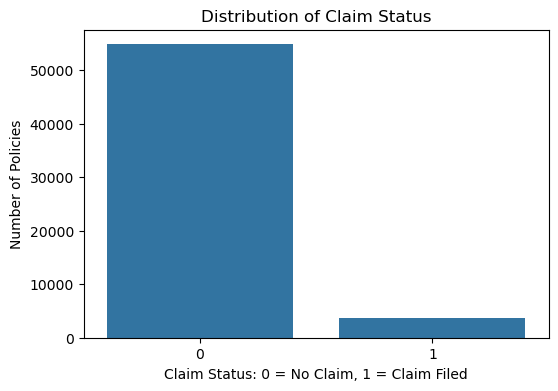

In [15]:
# Visualising target variable distribution

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="is_claim")
plt.title("Distribution of Claim Status")
plt.xlabel("Claim Status: 0 = No Claim, 1 = Claim Filed")
plt.ylabel("Number of Policies")
plt.show()

### Observation

The target variable is highly imbalanced. Most policyholders did not file a claim, while only a small percentage filed a claim. Therefore, accuracy alone may not be a reliable evaluation metric. Metrics such as Precision, Recall, F1 Score, and ROC-AUC should be used during model evaluation.

## 17. Separating Numerical and Categorical Columns

The dataset contains both numerical and categorical variables. Separating them helps in applying suitable preprocessing and visualization techniques.

In [16]:
# Separating numerical and categorical columns

numerical_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = df.select_dtypes(include=["object"]).columns.tolist()

print("Number of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

Number of numerical columns: 16
Number of categorical columns: 28

Numerical Columns:
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'make', 'airbags', 'displacement', 'cylinder', 'gear_box', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'ncap_rating', 'is_claim']

Categorical Columns:
['policy_id', 'area_cluster', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'transmission_type', 'steering_type', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']


### Observation

The dataset contains numerical columns such as policy tenure, age of car, age of policyholder, population density, vehicle dimensions, engine-related variables, and NCAP rating. It also contains categorical columns such as area cluster, vehicle segment, model, fuel type, engine type, transmission type, steering type, rear brake type, and multiple Yes/No safety feature columns.

## 18. Unique Values in Categorical Columns

Categorical columns are checked for unique values to identify inconsistent labels, spelling issues, unnecessary spaces, or formatting problems.

In [17]:
# Checking unique values in categorical columns

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Number of unique values:", df[col].nunique())
    print(df[col].unique())


Column: policy_id
Number of unique values: 58592
['ID00001' 'ID00002' 'ID00003' ... 'ID58590' 'ID58591' 'ID58592']

Column: area_cluster
Number of unique values: 22
['C1' 'C2' 'C3' 'C4' 'C5' 'C6' 'C7' 'C8' 'C9' 'C10' 'C11' 'C12' 'C13'
 'C14' 'C15' 'C16' 'C17' 'C18' 'C19' 'C20' 'C21' 'C22']

Column: segment
Number of unique values: 6
['A' 'C1' 'C2' 'B2' 'B1' 'Utility']

Column: model
Number of unique values: 11
['M1' 'M2' 'M3' 'M4' 'M5' 'M6' 'M7' 'M8' 'M9' 'M10' 'M11']

Column: fuel_type
Number of unique values: 3
['CNG' 'Petrol' 'Diesel']

Column: max_torque
Number of unique values: 9
['60Nm@3500rpm' '113Nm@4400rpm' '91Nm@4250rpm' '250Nm@2750rpm'
 '200Nm@3000rpm' '82.1Nm@3400rpm' '200Nm@1750rpm' '85Nm@3000rpm'
 '170Nm@4000rpm']

Column: max_power
Number of unique values: 9
['40.36bhp@6000rpm' '88.50bhp@6000rpm' '67.06bhp@5500rpm'
 '113.45bhp@4000rpm' '88.77bhp@4000rpm' '55.92bhp@5300rpm'
 '97.89bhp@3600rpm' '61.68bhp@6000rpm' '118.36bhp@5500rpm']

Column: engine_type
Number of unique 

### Observation

The categorical columns appear to have consistent labels. Most safety-related columns contain only `Yes` and `No` values. Other categorical columns such as area cluster, segment, model, fuel type, engine type, transmission type, rear brakes type, and steering type contain fixed categories.

## 19. Standardising Categorical Labels

Although the categorical labels appear mostly consistent, it is good practice to remove extra spaces and standardise text formatting for all categorical columns.

In [18]:
# Standardising categorical labels by removing leading/trailing spaces

for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip()

In [19]:
# Rechecking unique values after standardisation

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print("Number of unique values:", df[col].nunique())
    print(df[col].unique())


Column: policy_id
Number of unique values: 58592
['ID00001' 'ID00002' 'ID00003' ... 'ID58590' 'ID58591' 'ID58592']

Column: area_cluster
Number of unique values: 22
['C1' 'C2' 'C3' 'C4' 'C5' 'C6' 'C7' 'C8' 'C9' 'C10' 'C11' 'C12' 'C13'
 'C14' 'C15' 'C16' 'C17' 'C18' 'C19' 'C20' 'C21' 'C22']

Column: segment
Number of unique values: 6
['A' 'C1' 'C2' 'B2' 'B1' 'Utility']

Column: model
Number of unique values: 11
['M1' 'M2' 'M3' 'M4' 'M5' 'M6' 'M7' 'M8' 'M9' 'M10' 'M11']

Column: fuel_type
Number of unique values: 3
['CNG' 'Petrol' 'Diesel']

Column: max_torque
Number of unique values: 9
['60Nm@3500rpm' '113Nm@4400rpm' '91Nm@4250rpm' '250Nm@2750rpm'
 '200Nm@3000rpm' '82.1Nm@3400rpm' '200Nm@1750rpm' '85Nm@3000rpm'
 '170Nm@4000rpm']

Column: max_power
Number of unique values: 9
['40.36bhp@6000rpm' '88.50bhp@6000rpm' '67.06bhp@5500rpm'
 '113.45bhp@4000rpm' '88.77bhp@4000rpm' '55.92bhp@5300rpm'
 '97.89bhp@3600rpm' '61.68bhp@6000rpm' '118.36bhp@5500rpm']

Column: engine_type
Number of unique 

### Observation

Extra spaces, if any, have been removed from categorical columns. The categorical values are now standardised and ready for further analysis.

## 20. Checking Cardinality of Categorical Columns

Cardinality refers to the number of unique categories in a categorical column. High-cardinality columns can increase the number of dummy variables during encoding and may affect model complexity.

In [20]:
# Checking cardinality of categorical columns

cat_cardinality = pd.DataFrame({
    "Column": categorical_cols,
    "Unique_Values": [df[col].nunique() for col in categorical_cols]
}).sort_values(by="Unique_Values", ascending=False)

cat_cardinality

,Column,Unique_Values
0,policy_id,58592
1,area_cluster,22
3,model,11
7,engine_type,11
5,max_torque,9
6,max_power,9
2,segment,6
4,fuel_type,3
15,steering_type,3
22,is_central_locking,2


### Observation

The `policy_id` column has a unique value for each policy and acts as an identifier. It should not be used as a predictive feature during model building. Other categorical columns have manageable cardinality and can be used for EDA and encoding.

## 21. Dropping Identifier Column for Analysis Copy

The `policy_id` column is an identifier and does not carry predictive business meaning. Therefore, a separate analysis copy is created after removing `policy_id`. The original dataframe is kept unchanged for reference.

In [21]:
# Creating a copy of the dataframe for analysis and modelling

df_analysis = df.copy()

# Dropping policy_id from analysis copy
df_analysis = df_analysis.drop(columns=["policy_id"])

df_analysis.head()

,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
1,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
2,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2,No,No,No,Yes,No,Drum,796,3,Manual,5,Power,4.6,3445,1515,1475,1185,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0,0
3,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2,Yes,Yes,No,Yes,Yes,Drum,1197,4,Automatic,5,Electric,4.8,3995,1735,1515,1335,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2,No,No,No,No,Yes,Drum,999,3,Automatic,5,Electric,5.0,3731,1579,1490,1155,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


In [22]:
# Checking shape after dropping identifier column

df_analysis.shape

(58592, 43)

### Observation

After removing the identifier column `policy_id`, the analysis dataset contains 58,592 rows and 43 columns. This dataset will be used for EDA, feature engineering, and modelling preparation.

## 22. Updating Numerical and Categorical Columns After Dropping Identifier

Since the identifier column `policy_id` has been removed from the analysis dataset, numerical and categorical columns are updated again for further analysis.

In [23]:
# Updating numerical and categorical column lists after dropping policy_id

target_col = "is_claim"

numerical_cols_analysis = df_analysis.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols_analysis = df_analysis.select_dtypes(include=["object"]).columns.tolist()

# Removing target column from numerical columns for EDA feature analysis
if target_col in numerical_cols_analysis:
    numerical_features = [col for col in numerical_cols_analysis if col != target_col]
else:
    numerical_features = numerical_cols_analysis

categorical_features = categorical_cols_analysis

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Number of numerical features: 15
Number of categorical features: 27

Numerical Features:
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'make', 'airbags', 'displacement', 'cylinder', 'gear_box', 'turning_radius', 'length', 'width', 'height', 'gross_weight', 'ncap_rating']

Categorical Features:
['area_cluster', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'transmission_type', 'steering_type', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']


### Observation

After removing the identifier column and separating the target variable, the remaining columns are divided into numerical and categorical features. These features will be used for exploratory data analysis and later for model preparation.

## 23. Univariate Analysis of Numerical Features

Univariate analysis of numerical columns helps understand the distribution, spread, skewness, and possible outliers in each variable. Histograms are used to observe the distribution of numerical features.

In [24]:
# Displaying numerical feature summary

df_analysis[numerical_features].describe().T

,count,mean,std,min,25%,50%,75%,max
policy_tenure,58592.0,0.611246,0.414156,0.002735,0.210250,0.573792,1.039104,1.396641
age_of_car,58592.0,0.069424,0.056721,0.000000,0.020000,0.060000,0.110000,1.000000
age_of_policyholder,58592.0,0.469420,0.122886,0.288462,0.365385,0.451923,0.548077,1.000000
population_density,58592.0,18826.858667,17660.174792,290.000000,6112.000000,8794.000000,27003.000000,73430.000000
make,58592.0,1.763722,1.136988,1.000000,1.000000,1.000000,3.000000,5.000000
airbags,58592.0,3.137066,1.832641,1.000000,2.000000,2.000000,6.000000,6.000000
displacement,58592.0,1162.355851,266.304786,796.000000,796.000000,1197.000000,1493.000000,1498.000000
cylinder,58592.0,3.626963,0.483616,3.000000,3.000000,4.000000,4.000000,4.000000
gear_box,58592.0,5.245443,0.430353,5.000000,5.000000,5.000000,5.000000,6.000000
turning_radius,58592.0,4.852893,0.228061,4.500000,4.600000,4.800000,5.000000,5.200000


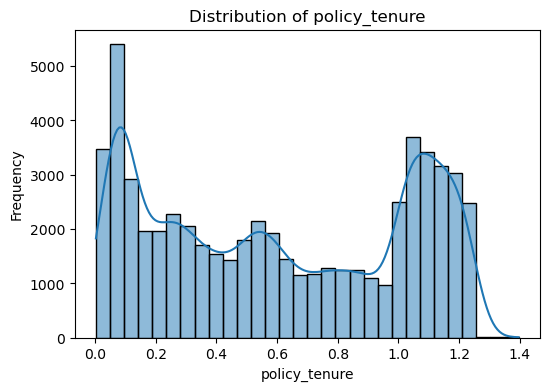

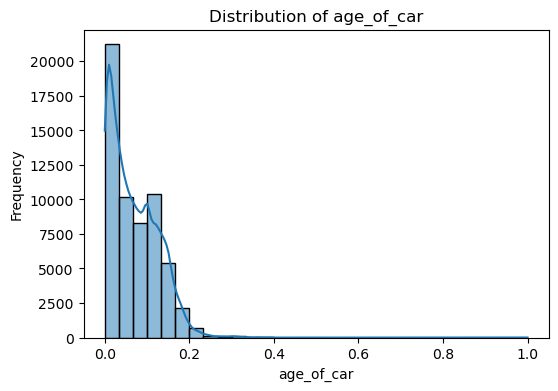

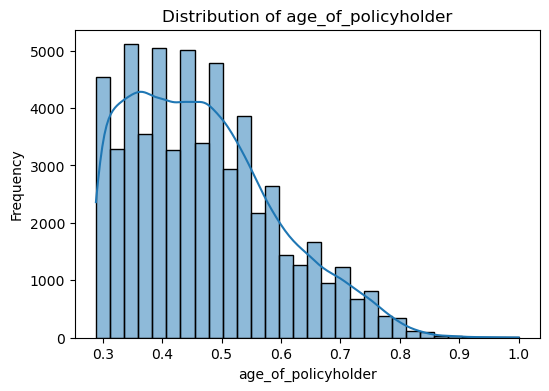

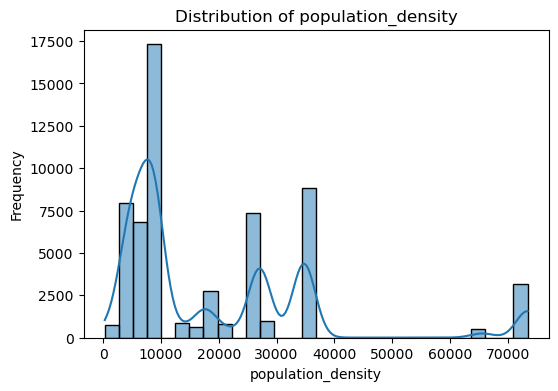

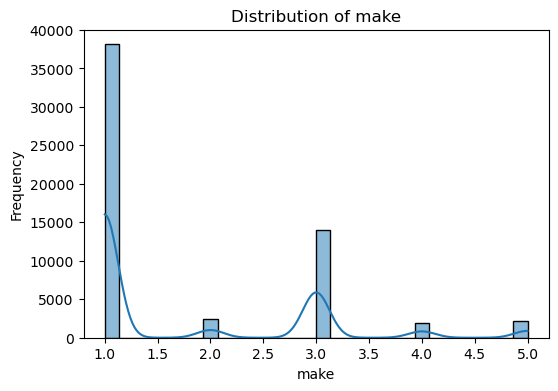

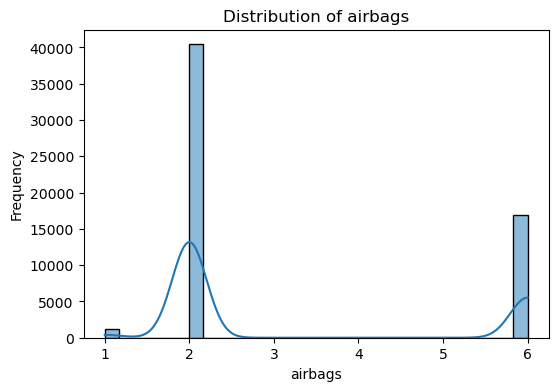

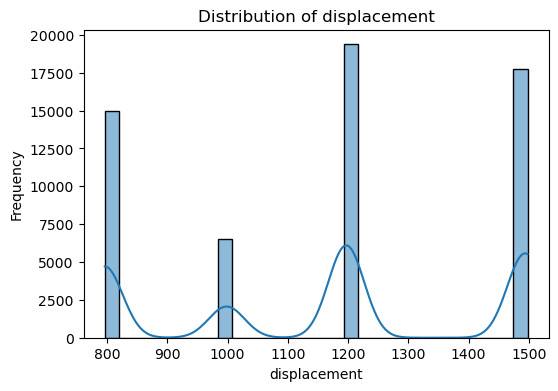

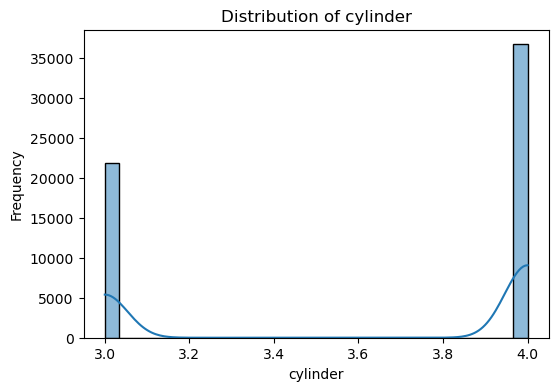

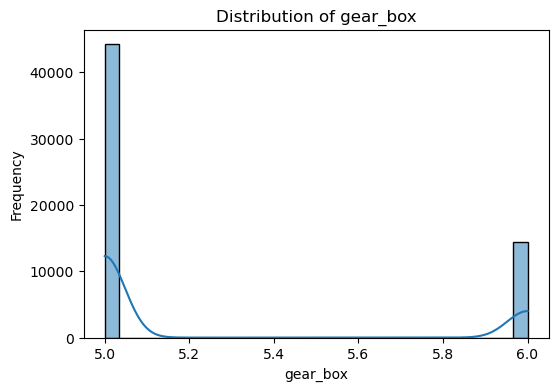

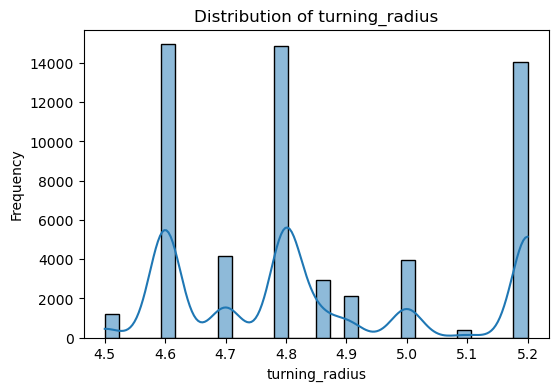

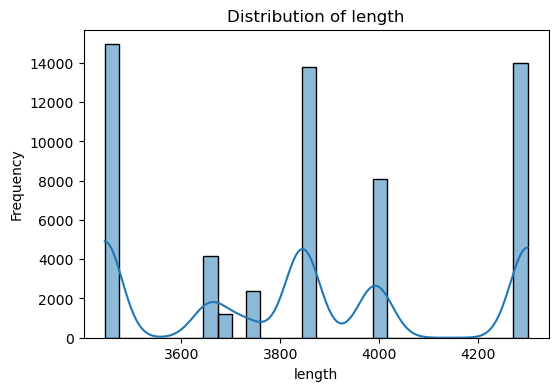

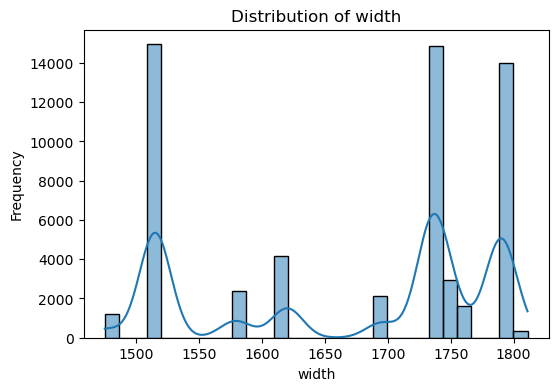

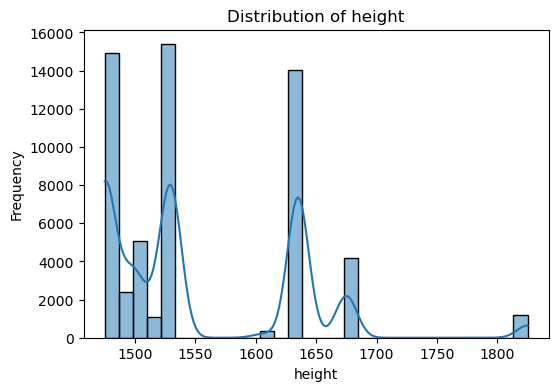

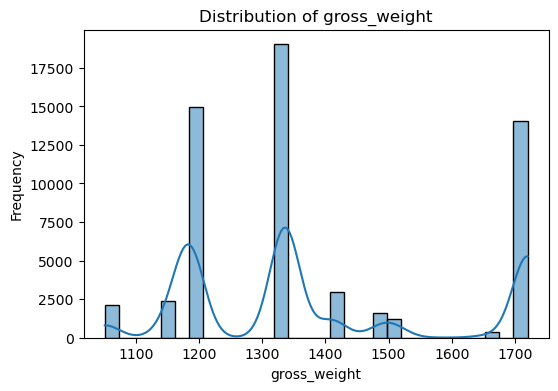

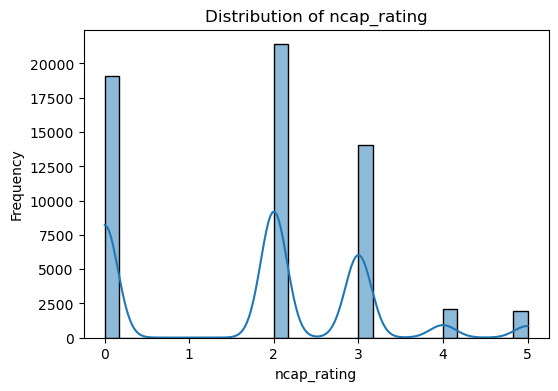

In [25]:
# Plotting histograms for numerical features

for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.histplot(df_analysis[col], kde=True, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

### Observation

The numerical features show different distributions. Some variables may appear skewed, while some may have concentrated ranges. The normalized variables such as `age_of_car` and `age_of_policyholder` are already scaled, so their values are expected to appear between a smaller range.

## 24. Boxplots for Numerical Features

Boxplots are used to visually inspect the spread of numerical features and detect possible outliers.

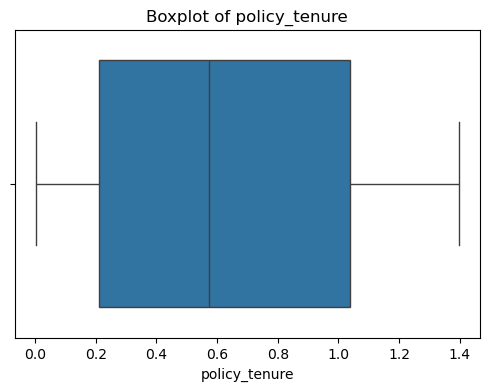

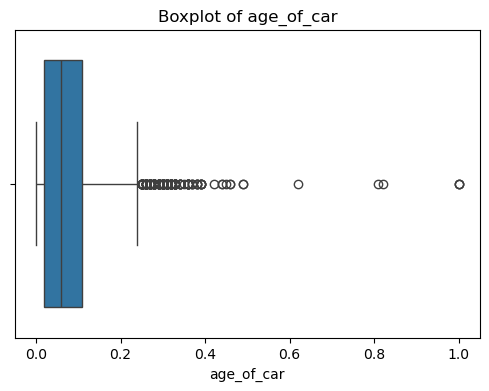

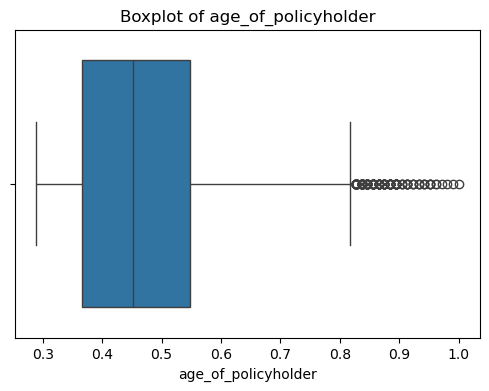

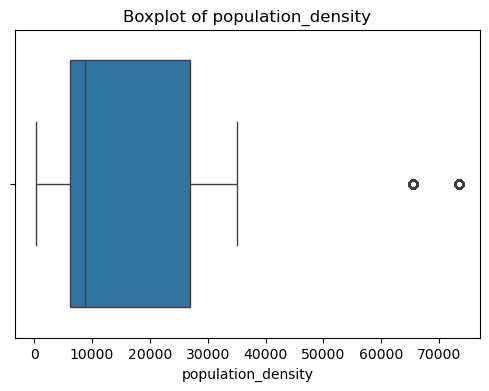

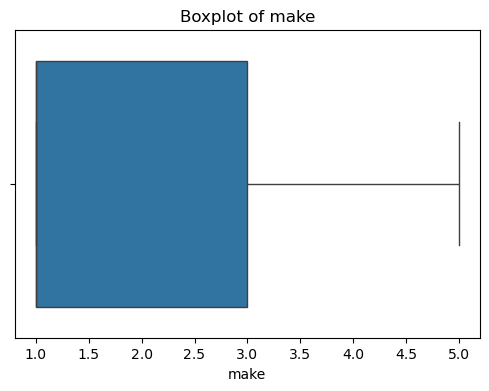

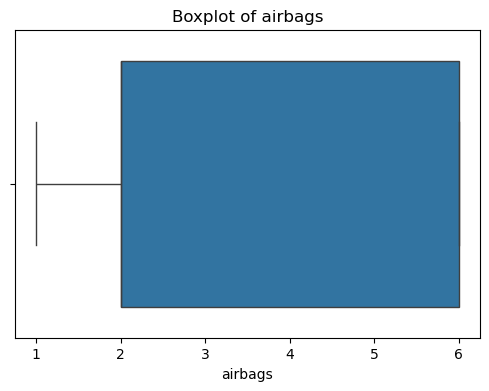

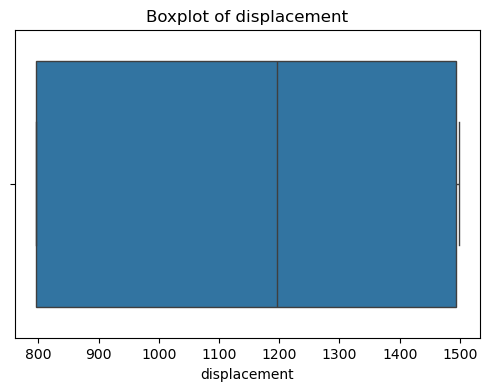

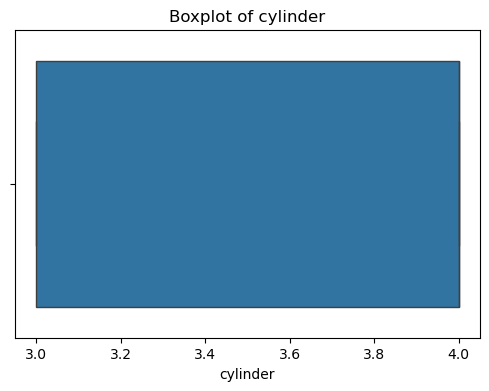

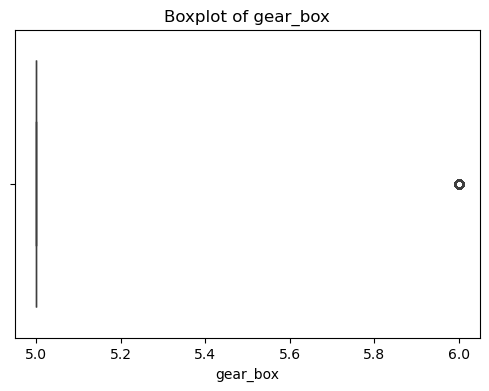

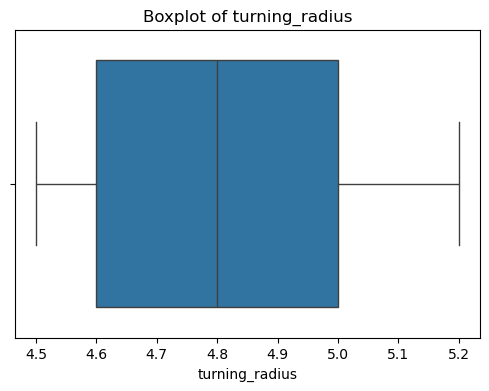

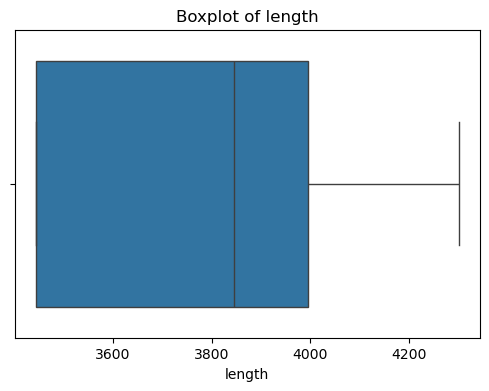

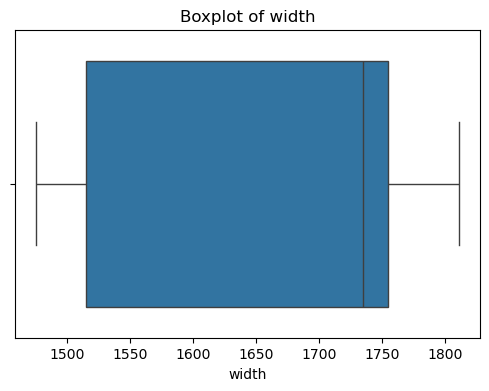

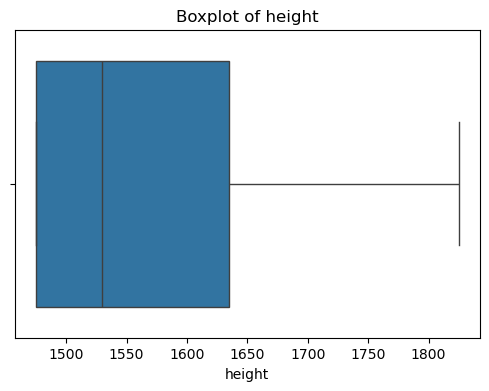

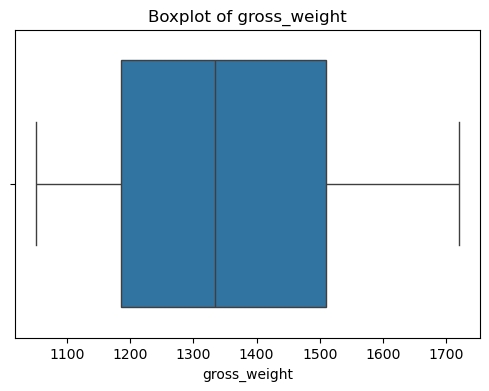

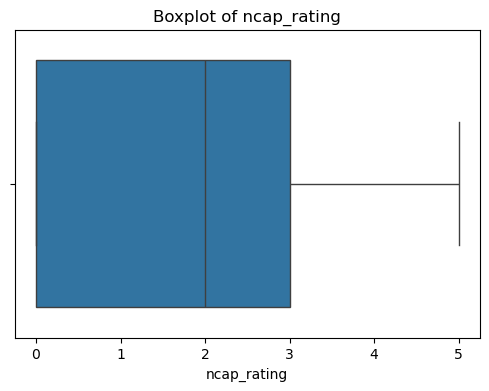

In [26]:
# Plotting boxplots for numerical features

for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(x=df_analysis[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

### Observation

The boxplots help identify features with possible outliers. Outlier treatment will be considered carefully because in insurance data, extreme values may sometimes carry useful risk-related information.

## 25. Skewness Check for Numerical Features

Skewness is checked to identify numerical features whose distributions are highly asymmetric. Highly skewed features may require transformation before modelling.

In [27]:
# Checking skewness of numerical features

skewness_df = pd.DataFrame({
    "Feature": numerical_features,
    "Skewness": [df_analysis[col].skew() for col in numerical_features]
}).sort_values(by="Skewness", ascending=False)

skewness_df

,Feature,Skewness
3,population_density,1.674178
4,make,1.197457
8,gear_box,1.183054
1,age_of_car,1.094081
12,height,1.035498
5,airbags,0.905946
2,age_of_policyholder,0.640049
13,gross_weight,0.546949
9,turning_radius,0.420983
10,length,0.145801


### Observation

The skewness values show whether numerical features are approximately symmetric or highly skewed. Features with high positive or negative skewness may be considered for transformation if required during preprocessing.

## 26. Univariate Analysis of Categorical Features

Categorical variables are analysed using count plots. This helps understand the frequency distribution of different categories within each categorical feature.

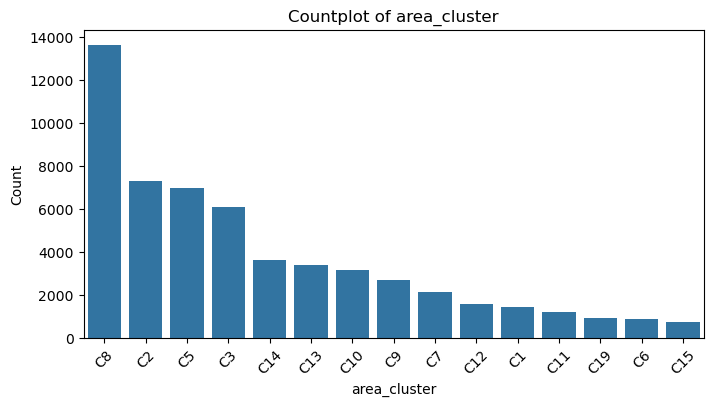

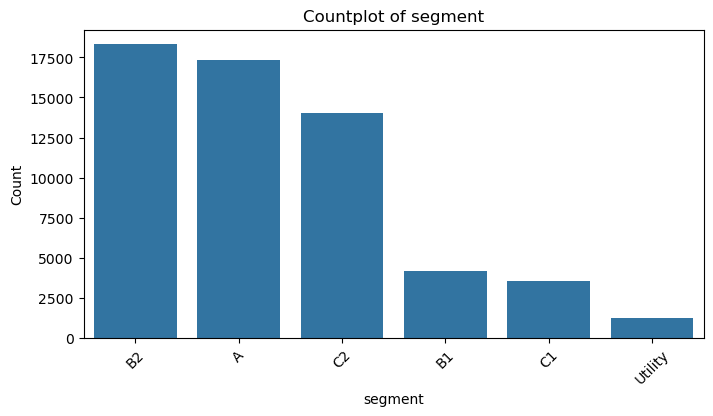

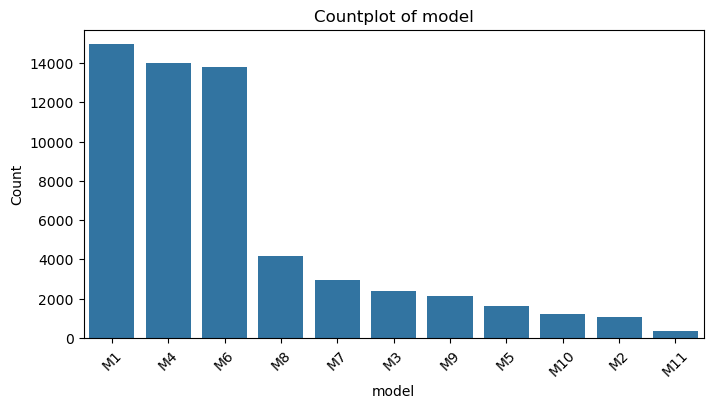

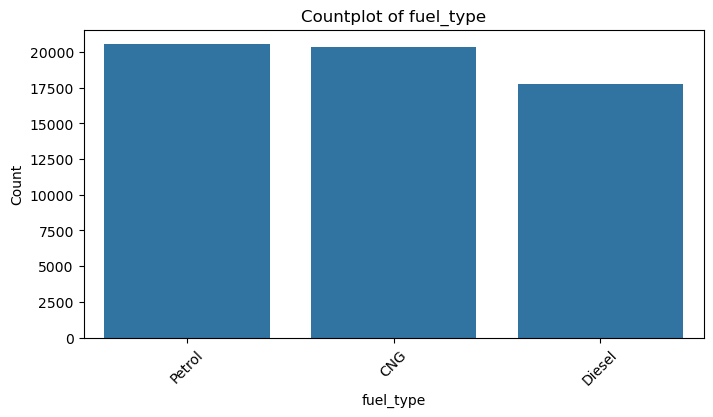

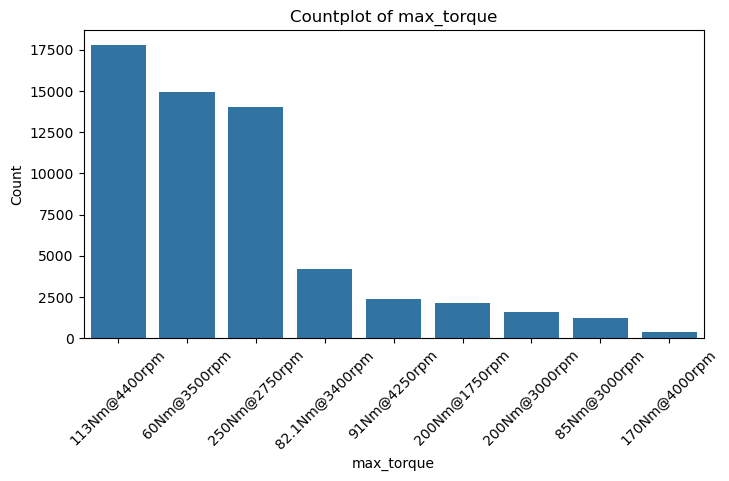

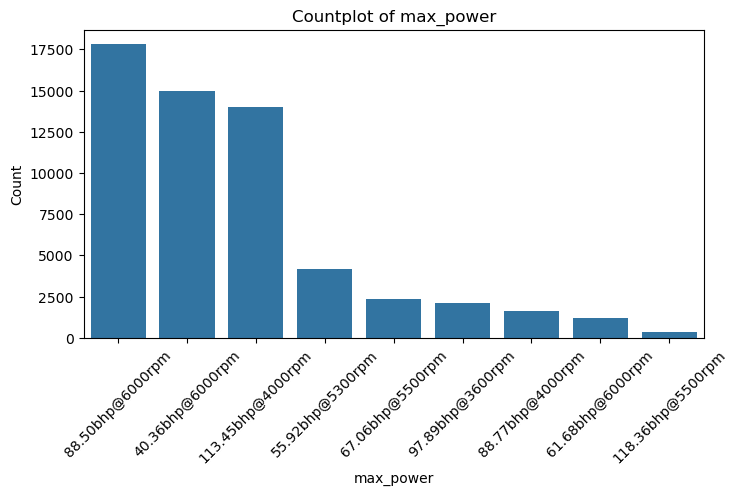

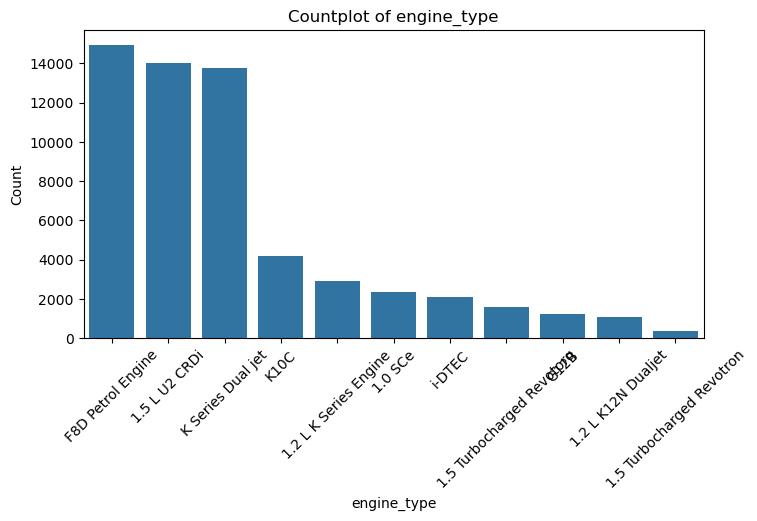

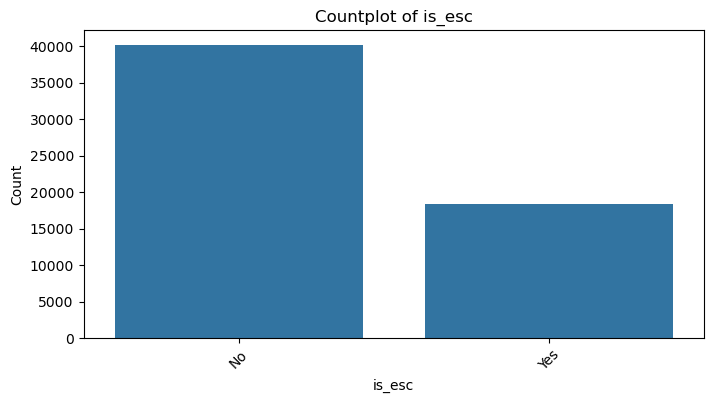

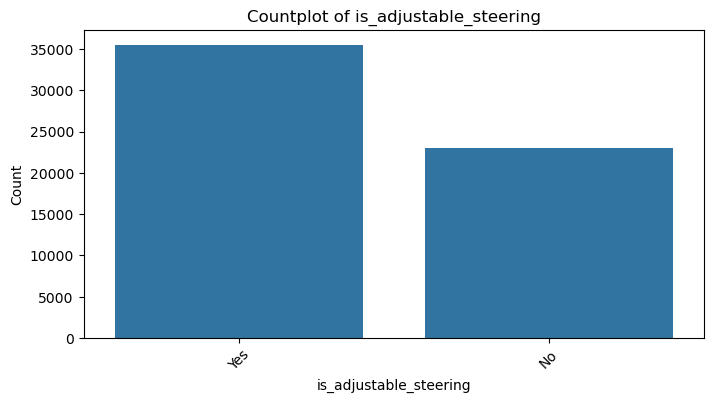

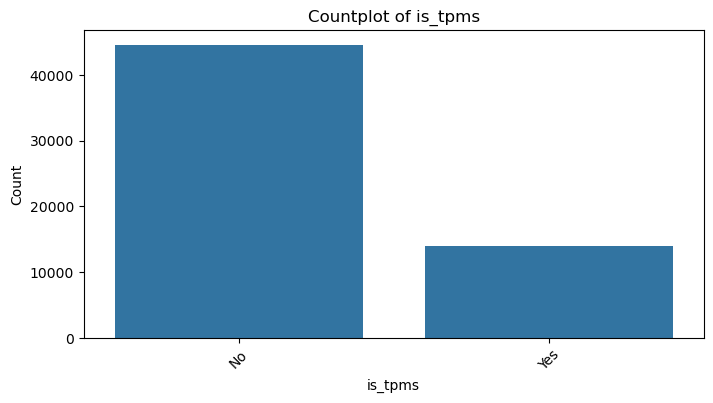

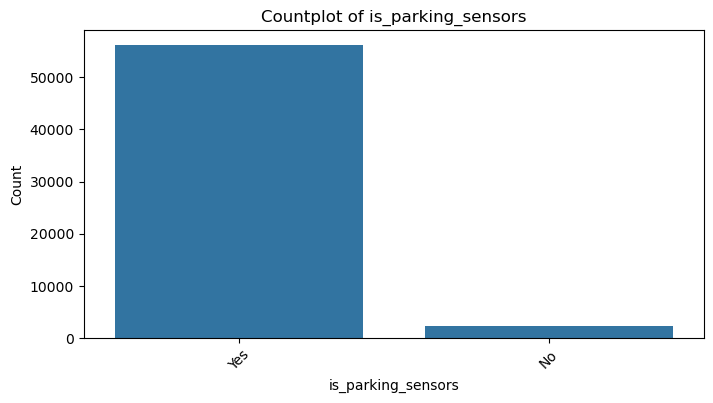

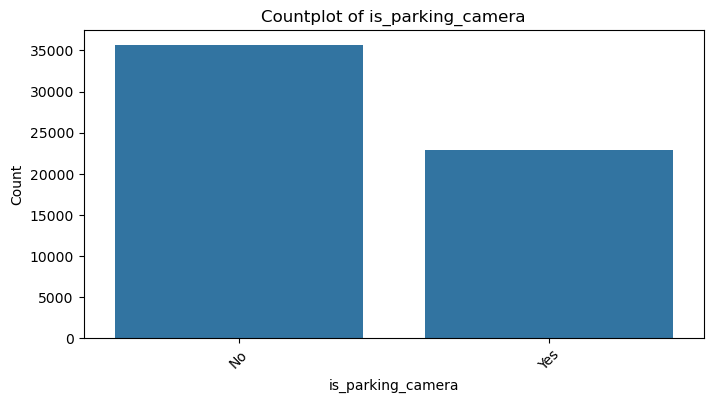

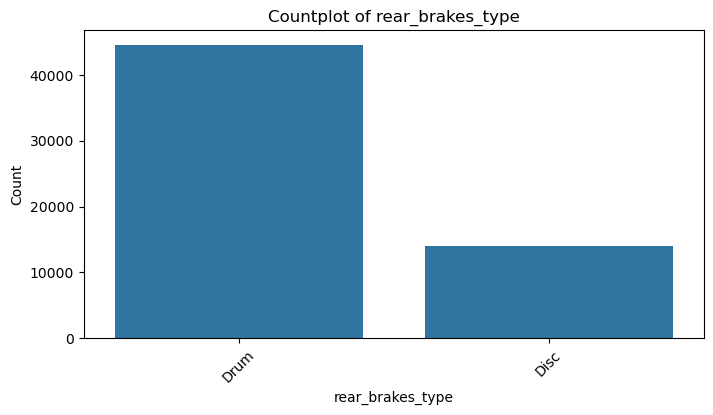

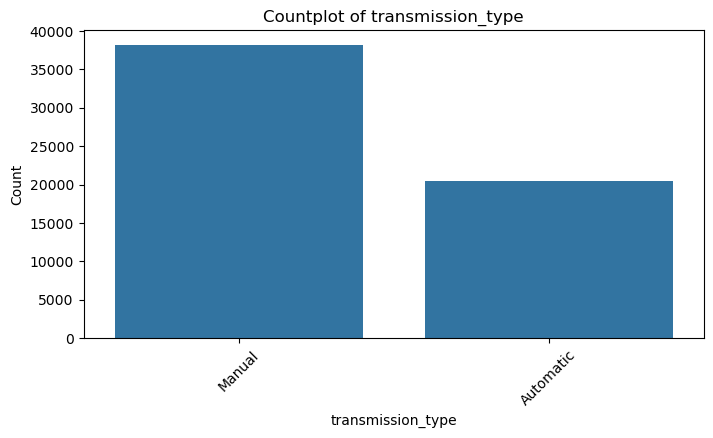

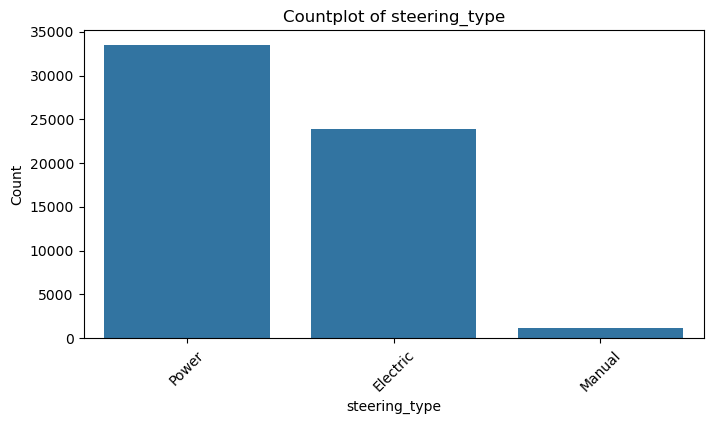

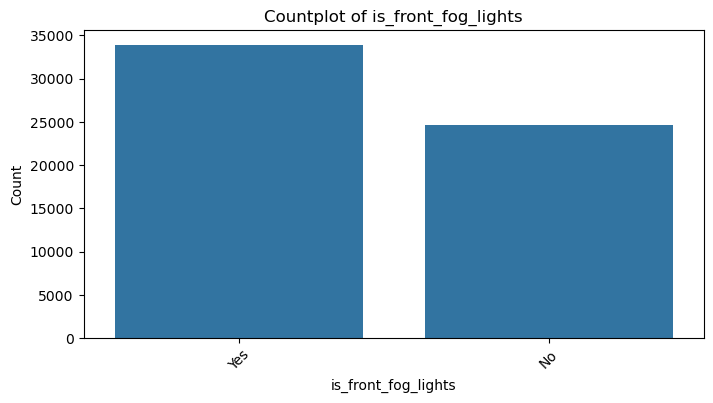

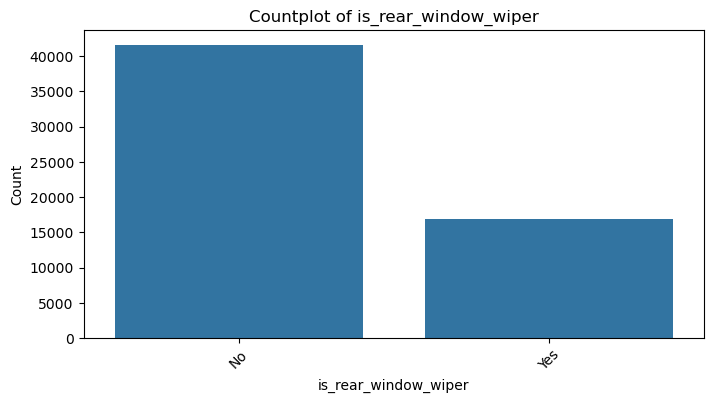

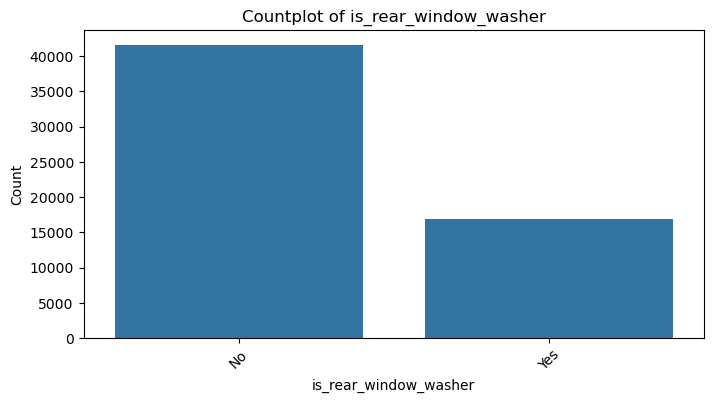

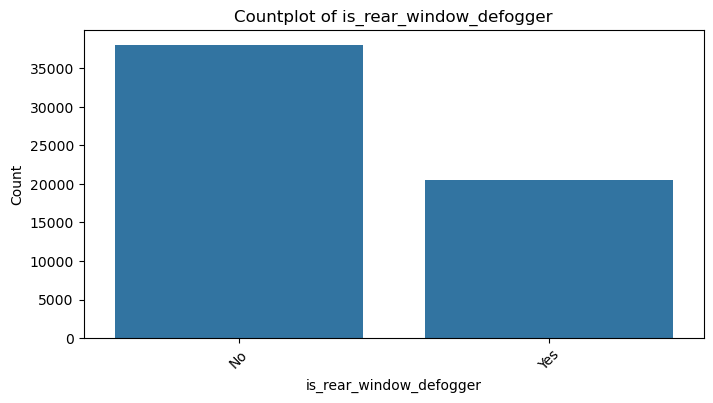

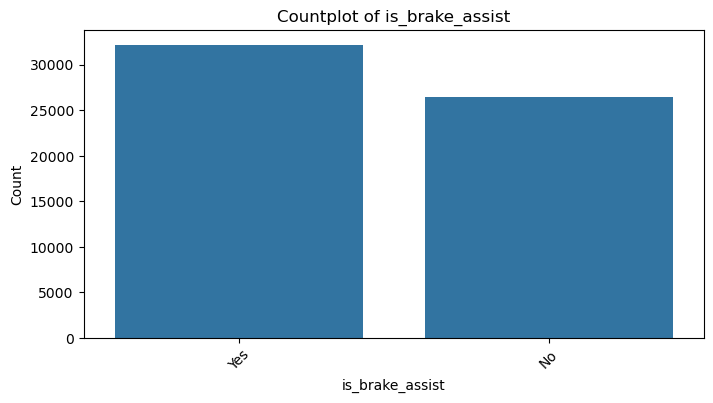

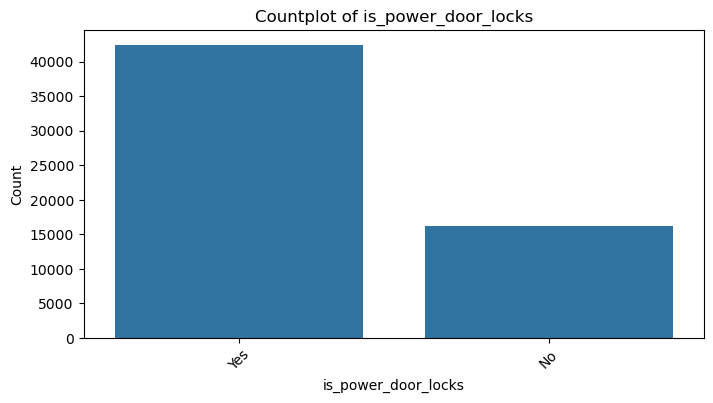

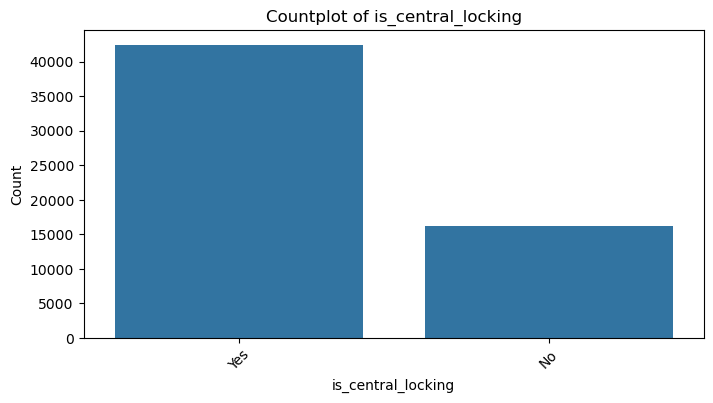

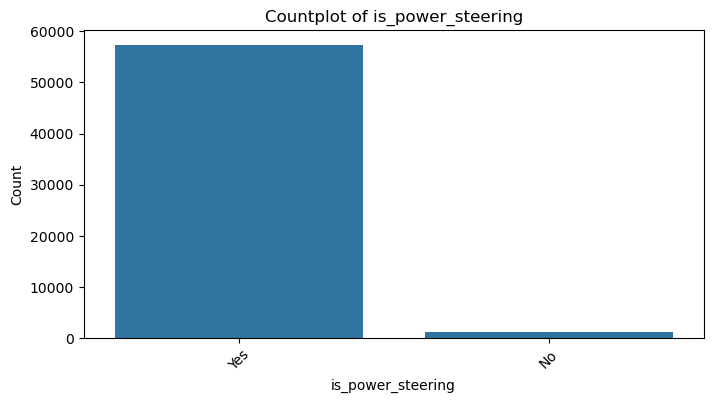

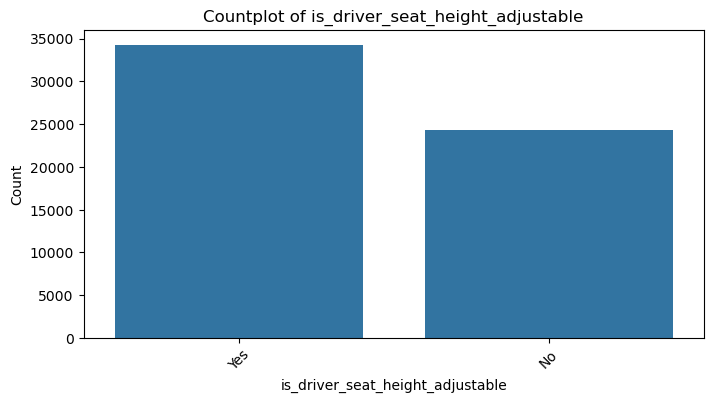

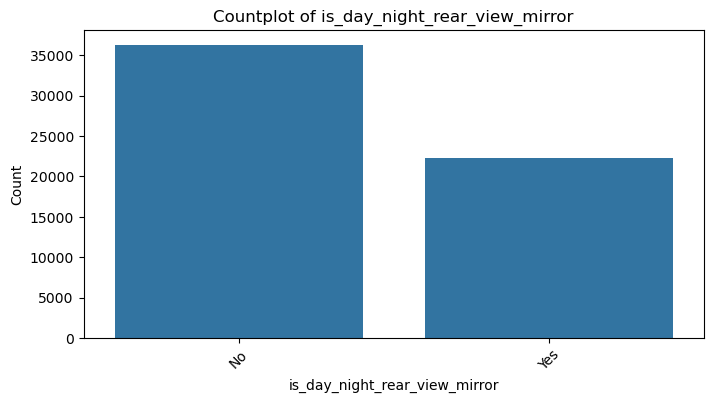

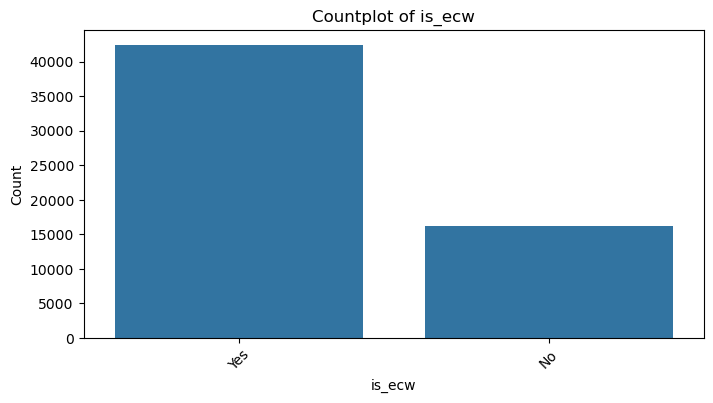

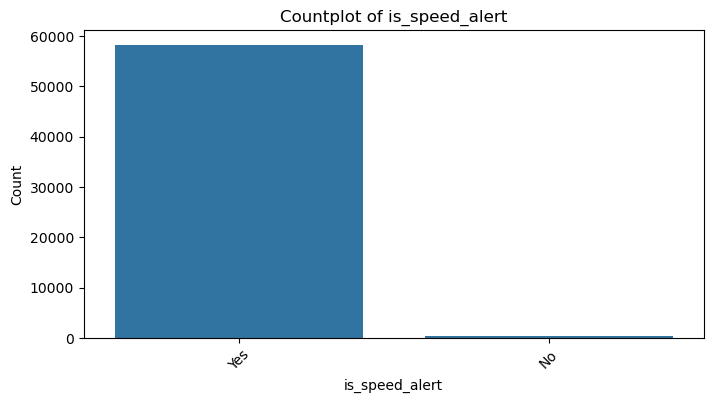

In [28]:
# Countplots for categorical features

for col in categorical_features:
    plt.figure(figsize=(8, 4))
    
    # Showing only top 15 categories if a column has many unique values
    order = df_analysis[col].value_counts().head(15).index
    
    sns.countplot(data=df_analysis, x=col, order=order)
    plt.title(f"Countplot of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

### Observation

Categorical features show the distribution of different groups such as area cluster, vehicle segment, model, fuel type, transmission type, steering type, rear brakes type, and safety feature availability. For high-cardinality columns, only the top categories are displayed for better readability.

## 27. Summary of Univariate Analysis

The univariate analysis helped identify the distribution of numerical and categorical variables. Numerical variables were analysed using histograms and boxplots, while categorical variables were analysed using countplots. This gives an initial understanding of feature behaviour before studying their relationship with the target variable.

## 28. Bivariate Analysis

Bivariate analysis is performed to understand the relationship between independent features and the target variable `is_claim`.

Since `is_claim` is a binary target variable, we compare numerical and categorical features against claim status to identify possible claim-risk patterns.

## 29. Claim Rate by Target Variable

Before analysing other features, the overall claim rate is calculated. This gives a baseline claim percentage for the full dataset.

In [29]:
# Calculating overall claim rate

overall_claim_rate = df_analysis["is_claim"].mean() * 100
print("Overall Claim Rate: {:.2f}%".format(overall_claim_rate))

Overall Claim Rate: 6.40%


### Observation

The overall claim rate shows the percentage of policyholders who filed a claim. This baseline will be used to compare claim rates across different customer, vehicle, and safety-related groups.

## 30. Numerical Features vs Claim Status

Numerical features are compared against the target variable using boxplots. This helps identify whether claim and no-claim groups show different distributions for numerical variables.

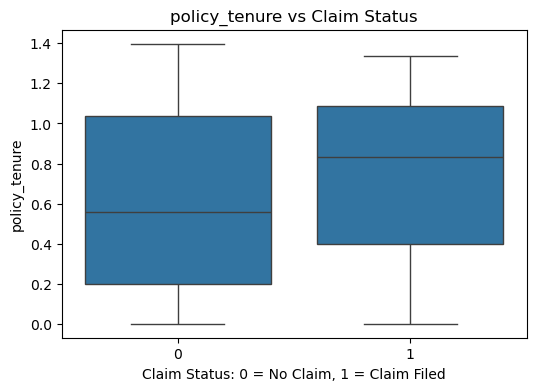

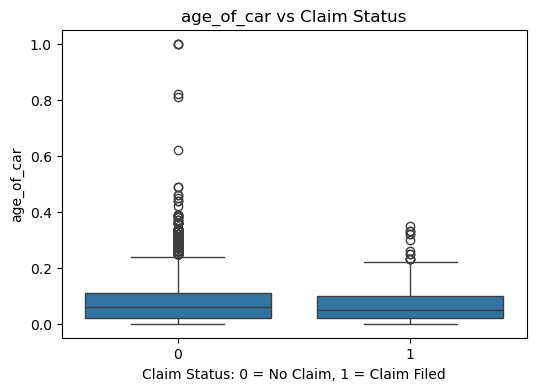

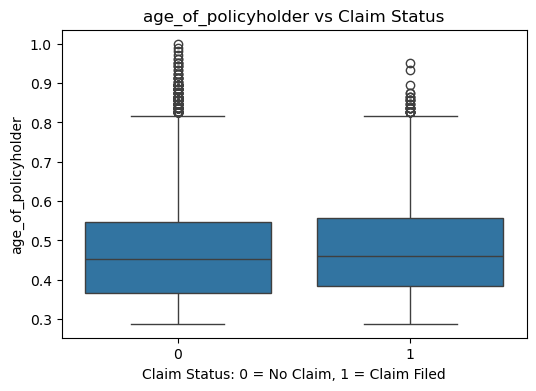

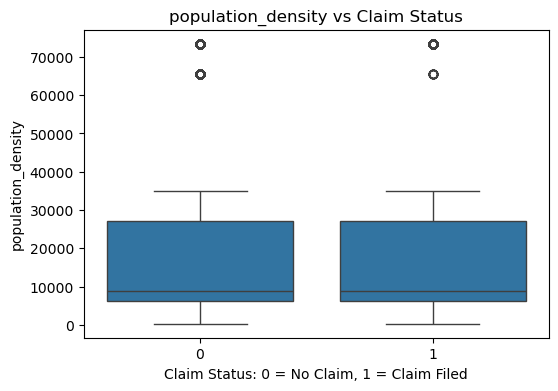

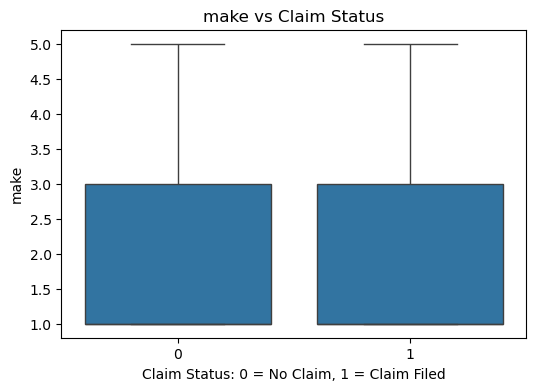

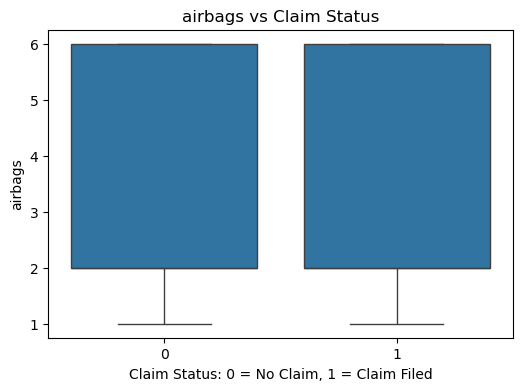

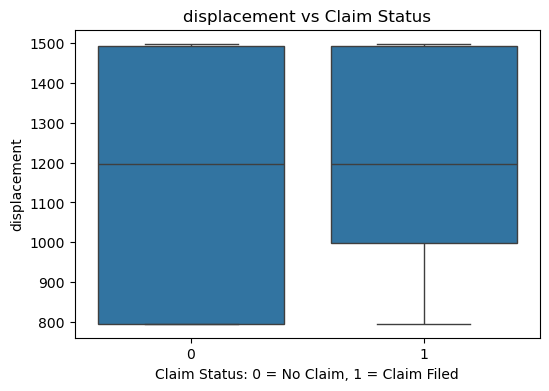

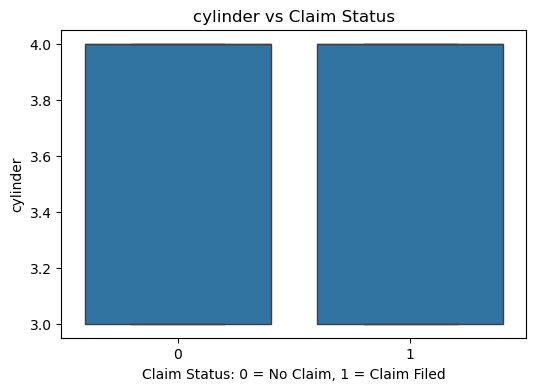

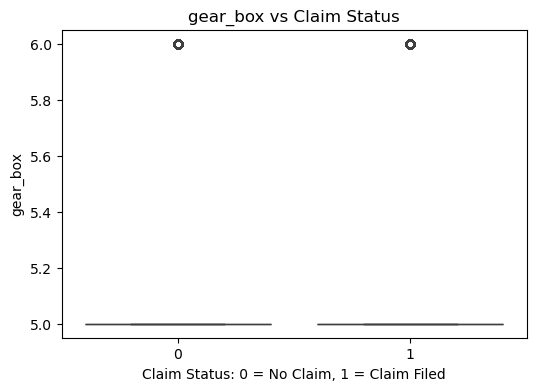

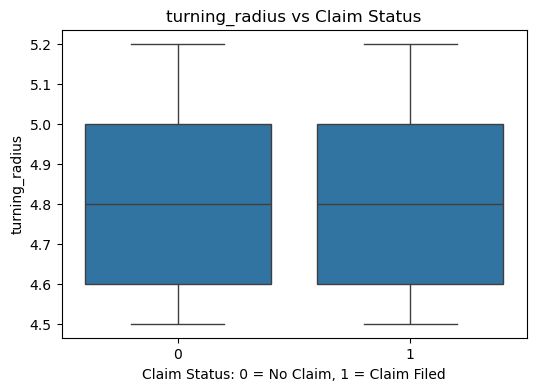

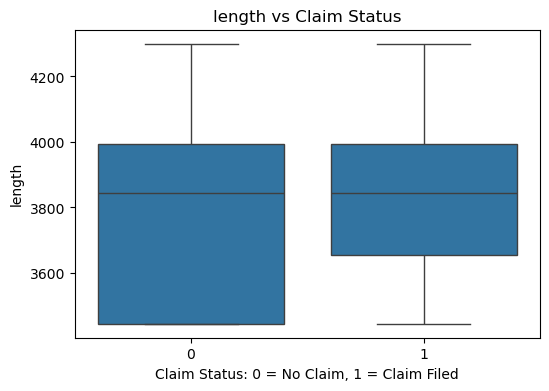

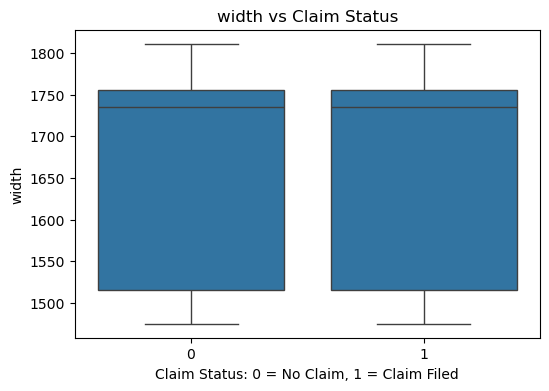

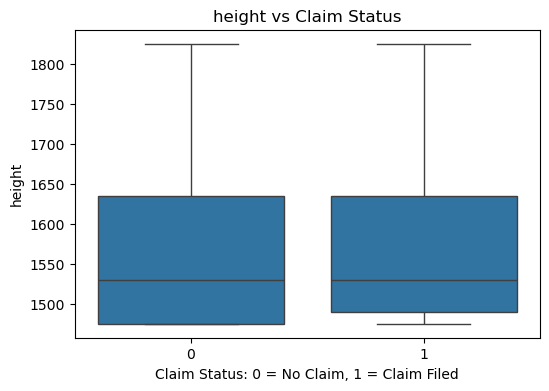

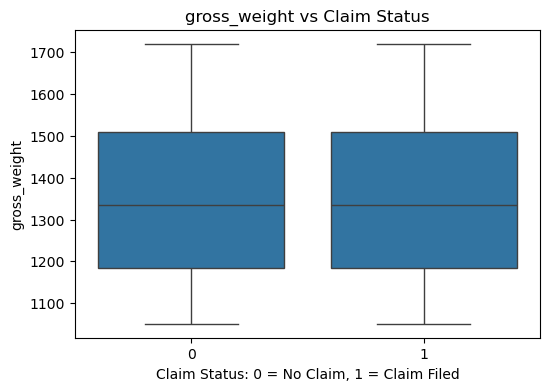

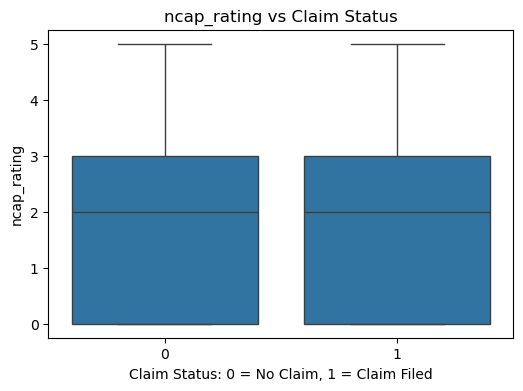

In [30]:
# Boxplots of numerical features against claim status

for col in numerical_features:
    plt.figure(figsize=(6, 4))
    sns.boxplot(data=df_analysis, x="is_claim", y=col)
    plt.title(f"{col} vs Claim Status")
    plt.xlabel("Claim Status: 0 = No Claim, 1 = Claim Filed")
    plt.ylabel(col)
    plt.show()

### Observation

The boxplots help compare the distribution of numerical variables between claim and no-claim groups. Features showing noticeable differences between the two groups may be useful predictors for claim risk.

## 31. Mean Numerical Values by Claim Status

The mean value of each numerical feature is compared for claim and no-claim groups. This helps identify numerical variables that differ between both classes.

In [31]:
# Mean values of numerical features grouped by claim status

numeric_claim_summary = df_analysis.groupby("is_claim")[numerical_features].mean().T
numeric_claim_summary.columns = ["No_Claim_Mean", "Claim_Mean"]

# Difference between claim and no-claim mean
numeric_claim_summary["Difference"] = numeric_claim_summary["Claim_Mean"] - numeric_claim_summary["No_Claim_Mean"]

numeric_claim_summary.sort_values(by="Difference", ascending=False)

,No_Claim_Mean,Claim_Mean,Difference
displacement,1161.821348,1170.177161,8.355813
length,3849.948107,3858.214514,8.266407
width,1671.942200,1676.498666,4.556466
gross_weight,1385.060554,1388.441302,3.380748
policy_tenure,0.602720,0.736002,0.133282
cylinder,3.625264,3.651814,0.026550
ncap_rating,1.758570,1.780149,0.021580
airbags,3.135730,3.156617,0.020886
age_of_policyholder,0.468699,0.479966,0.011267
turning_radius,4.852730,4.855269,0.002539


### Observation

The table compares average numerical feature values for policyholders who filed claims and those who did not. Features with larger differences may have stronger association with claim behaviour.

## 32. Categorical Features vs Claim Status

Categorical features are analysed by calculating claim rate for each category. Since `is_claim` contains 0 and 1 values, the mean of `is_claim` represents the claim rate.

In [32]:
# Claim rate by categorical features

for col in categorical_features:
    print("\n" + "="*80)
    print(f"Claim Rate by {col}")
    print("="*80)
    
    claim_rate_table = df_analysis.groupby(col).agg(
        Total_Policies=("is_claim", "count"),
        Total_Claims=("is_claim", "sum"),
        Claim_Rate=("is_claim", "mean")
    ).reset_index()
    
    claim_rate_table["Claim_Rate"] = claim_rate_table["Claim_Rate"] * 100
    claim_rate_table = claim_rate_table.sort_values(by="Claim_Rate", ascending=False)
    
    display(claim_rate_table)


Claim Rate by area_cluster


,area_cluster,Total_Policies,Total_Claims,Claim_Rate
9,C18,242,26,10.743802
14,C22,207,17,8.212560
5,C14,3660,281,7.677596
16,C4,665,51,7.669173
13,C21,379,29,7.651715
10,C19,952,71,7.457983
15,C3,6101,433,7.097197
11,C2,7342,520,7.082539
20,C8,13654,954,6.986964
18,C6,890,55,6.179775



Claim Rate by segment


,segment,Total_Policies,Total_Claims,Claim_Rate
2,B2,18314,1256,6.858141
4,C2,14018,901,6.427450
3,C1,3557,228,6.409896
0,A,17321,1046,6.038912
5,Utility,1209,73,6.038048
1,B1,4173,244,5.847112



Claim Rate by model


...

,is_day_night_rear_view_mirror,Total_Policies,Total_Claims,Claim_Rate
1,Yes,22283,1481,6.646322
0,No,36309,2267,6.243631



Claim Rate by is_ecw


,is_ecw,Total_Policies,Total_Claims,Claim_Rate
1,Yes,42435,2757,6.496995
0,No,16157,991,6.133564



Claim Rate by is_speed_alert


,is_speed_alert,Total_Policies,Total_Claims,Claim_Rate
1,Yes,58229,3733,6.410895
0,No,363,15,4.132231


### Observation

The claim rate tables show how claim percentage changes across different categories. Categories with higher claim rates may represent higher-risk groups and can be useful for business recommendations and model building.

## 33. Visualising Claim Rate for Categorical Features

Claim rate is visualised for categorical variables to easily identify high-risk and low-risk categories.

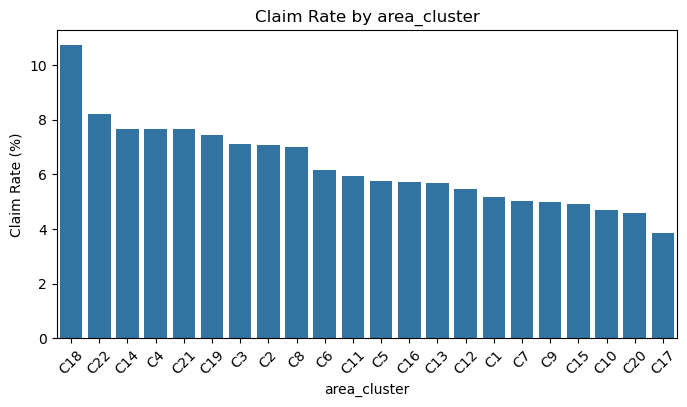

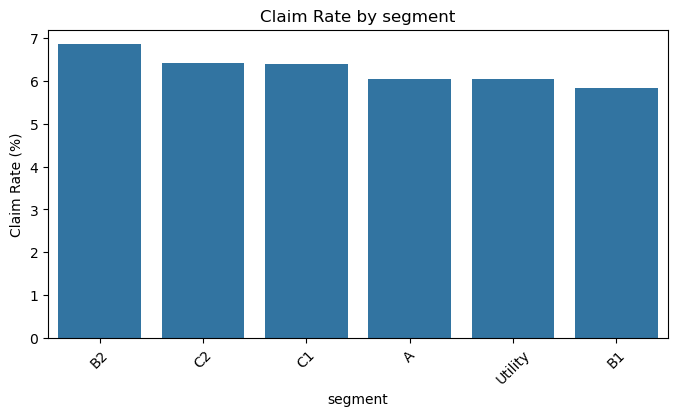

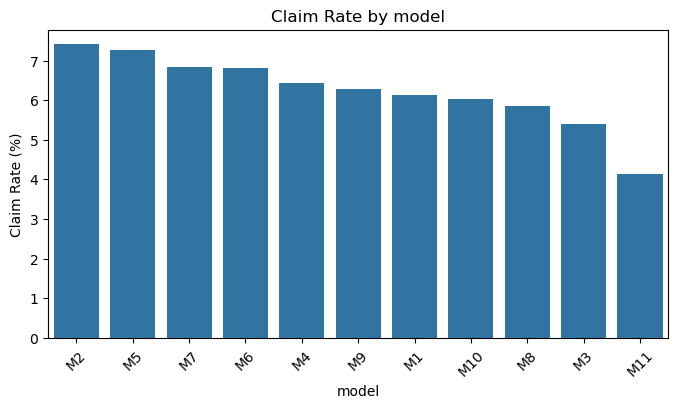

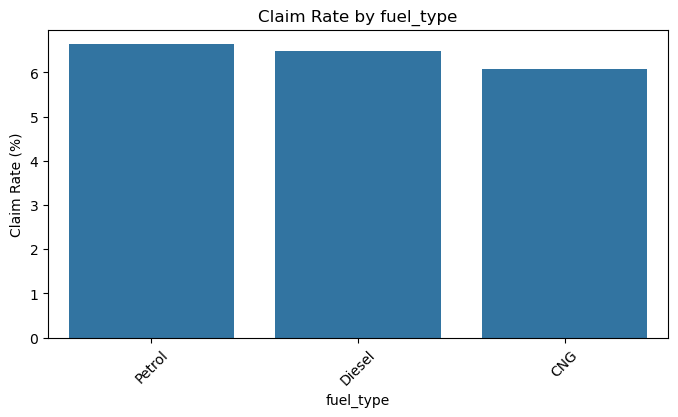

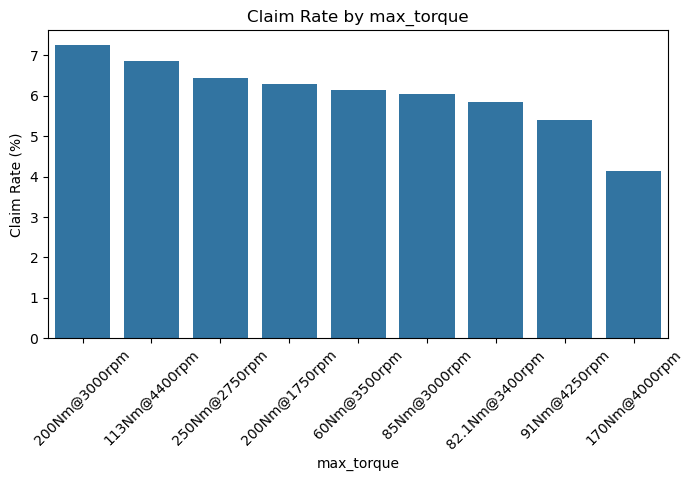

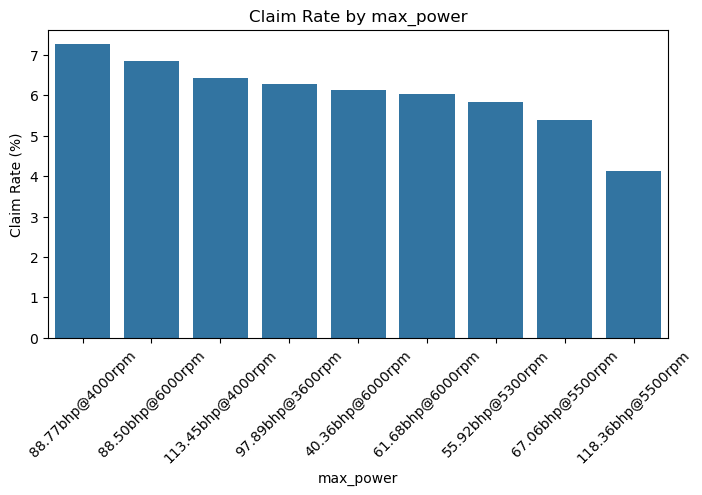

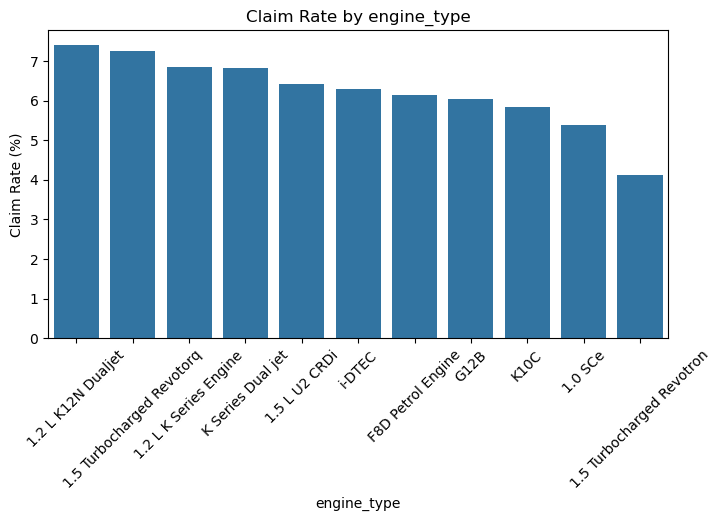

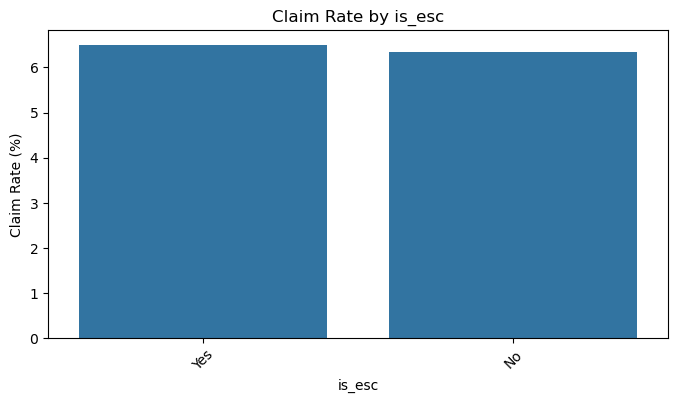

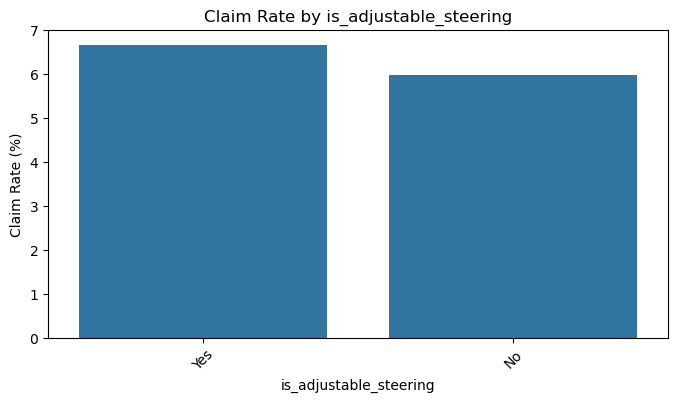

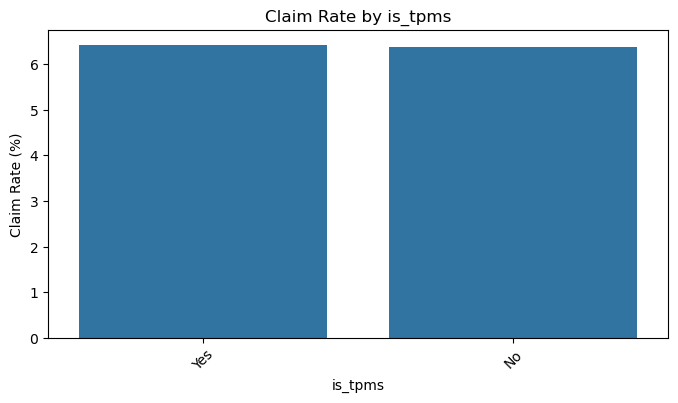

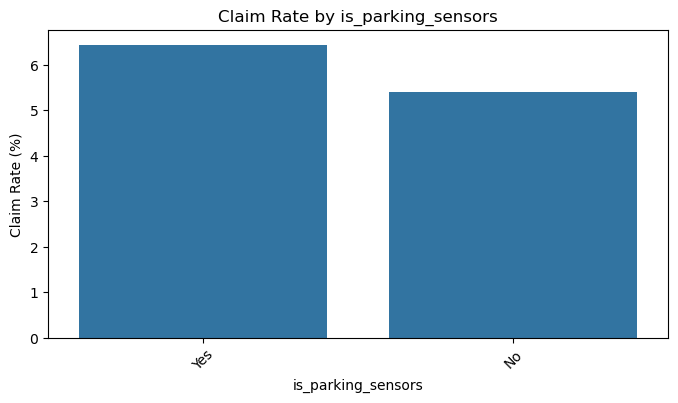

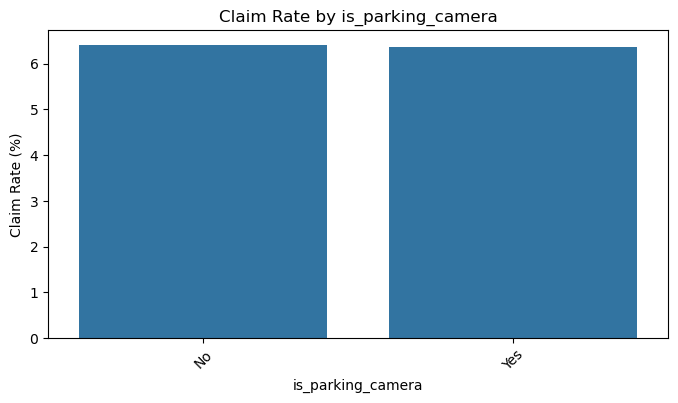

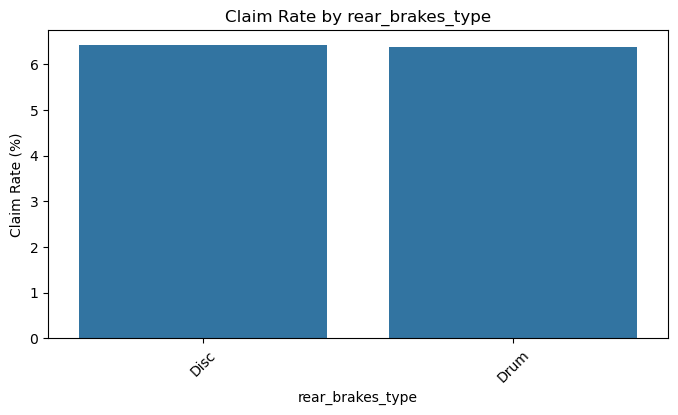

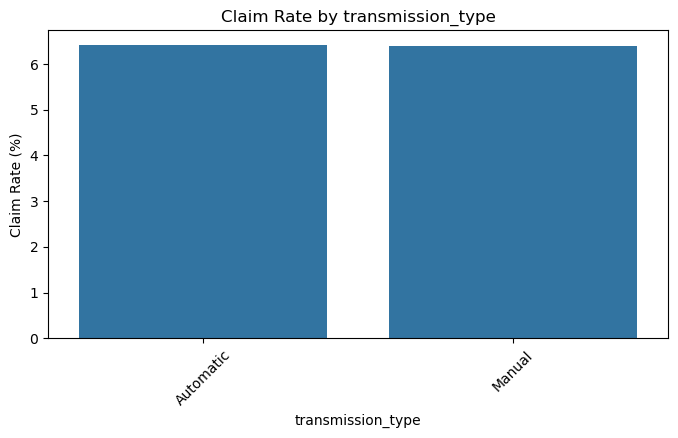

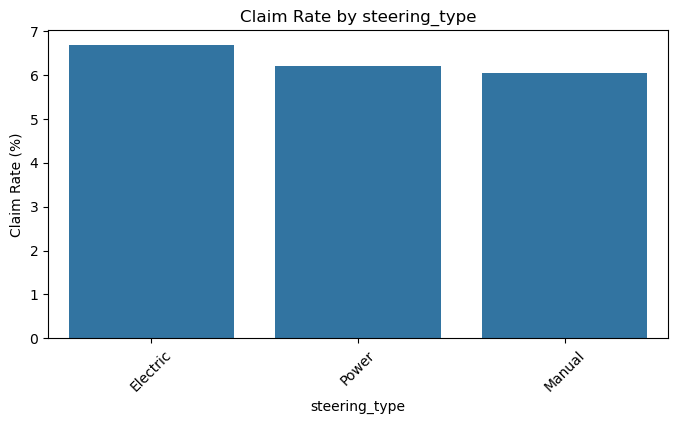

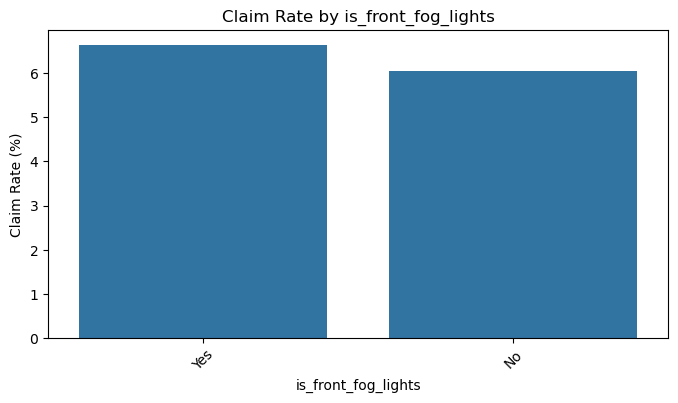

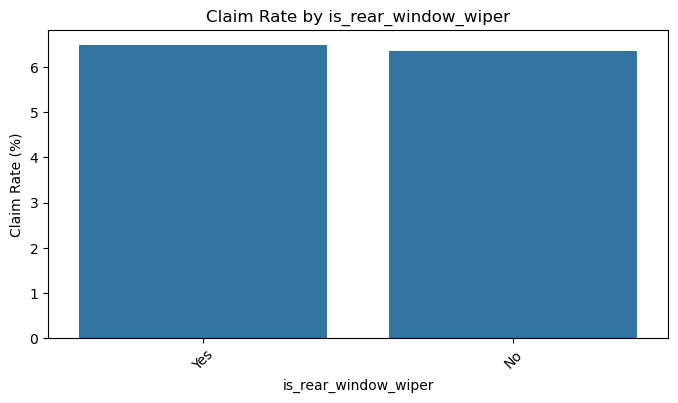

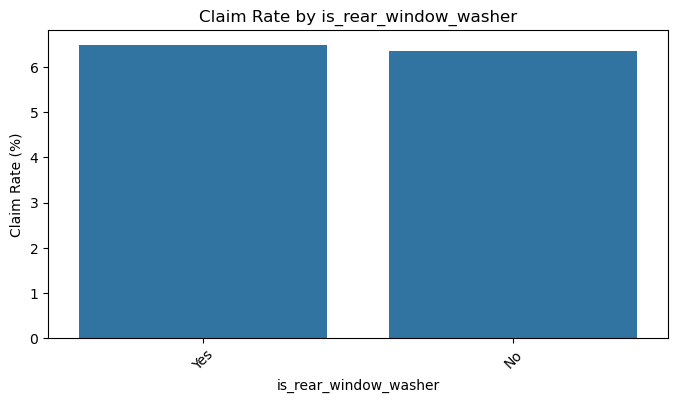

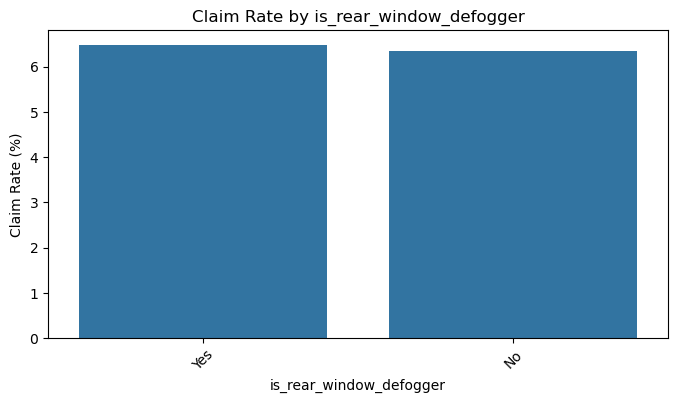

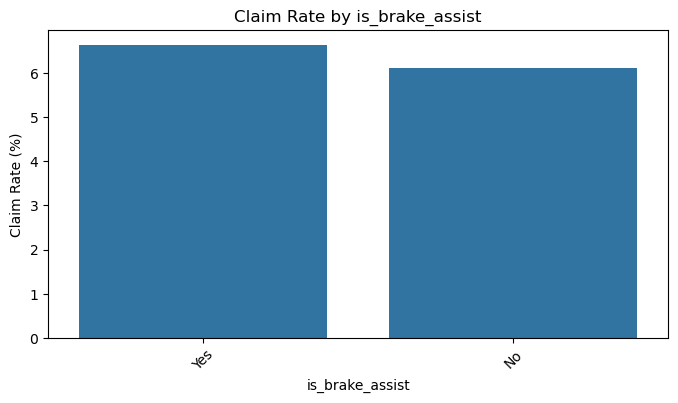

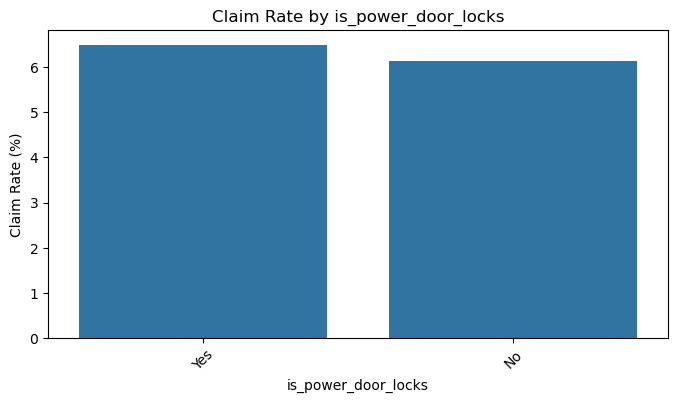

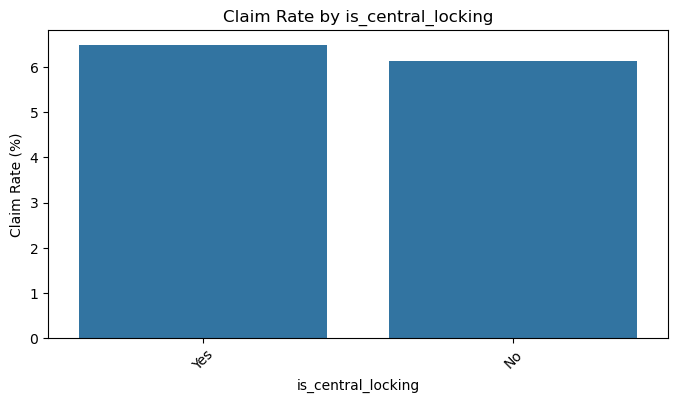

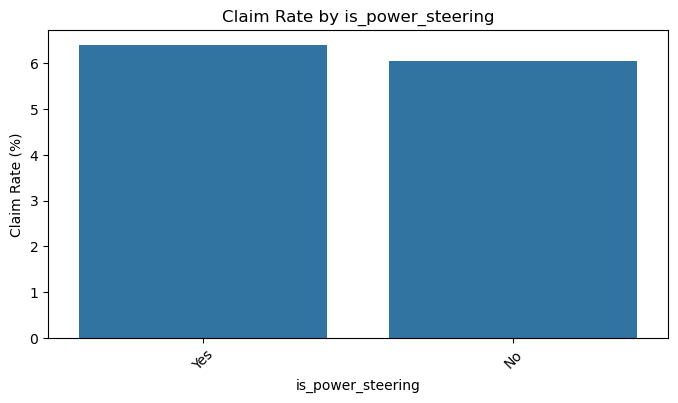

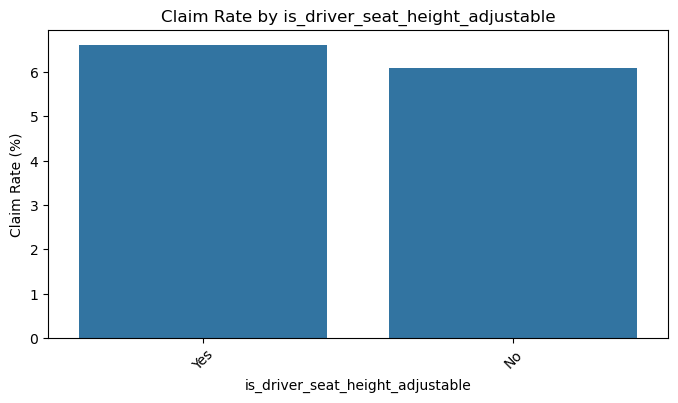

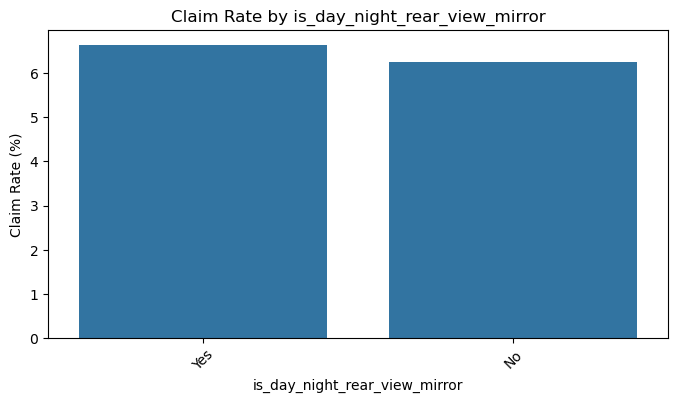

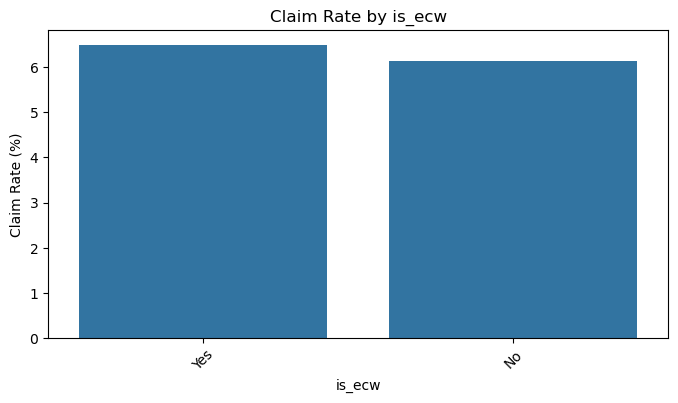

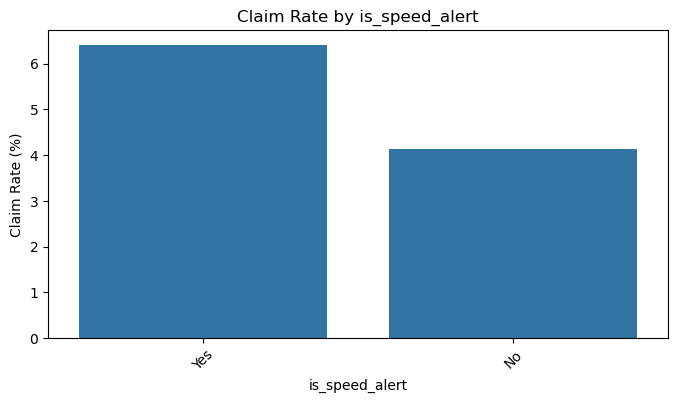

In [33]:
# Bar plots for claim rate across categorical features

for col in categorical_features:
    claim_rate = df_analysis.groupby(col)["is_claim"].mean().sort_values(ascending=False) * 100
    
    plt.figure(figsize=(8, 4))
    sns.barplot(x=claim_rate.index, y=claim_rate.values)
    plt.title(f"Claim Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Claim Rate (%)")
    plt.xticks(rotation=45)
    plt.show()

### Observation

The claim rate bar plots help visually compare claim behaviour across categories. Categories with claim rates above the overall claim rate may need closer attention from underwriting and risk teams.

## 34. Top High-Risk Categories Across Categorical Features

To make the analysis more business-friendly, the top high-risk categories are identified based on claim rate. Categories with very few records can give misleading claim rates, so a minimum policy count filter is applied.

In [34]:
# Finding top high-risk categories across categorical features

high_risk_categories = []

for col in categorical_features:
    temp = df_analysis.groupby(col).agg(
        Total_Policies=("is_claim", "count"),
        Total_Claims=("is_claim", "sum"),
        Claim_Rate=("is_claim", "mean")
    ).reset_index()
    
    temp["Claim_Rate"] = temp["Claim_Rate"] * 100
    temp["Feature"] = col
    temp = temp.rename(columns={col: "Category"})
    
    # Keeping categories with enough records to avoid misleading results
    temp = temp[temp["Total_Policies"] >= 100]
    
    high_risk_categories.append(temp)

high_risk_categories_df = pd.concat(high_risk_categories, ignore_index=True)

high_risk_categories_df.sort_values(by="Claim_Rate", ascending=False).head(20)

,Category,Total_Policies,Total_Claims,Claim_Rate,Feature
9,C18,242,26,10.743802,area_cluster
14,C22,207,17,8.212560,area_cluster
5,C14,3660,281,7.677596,area_cluster
16,C4,665,51,7.669173,area_cluster
13,C21,379,29,7.651715,area_cluster
10,C19,952,71,7.457983,area_cluster
62,1.2 L K12N Dualjet,1080,80,7.407407,engine_type
31,M2,1080,80,7.407407,model
45,200Nm@3000rpm,1598,116,7.259074,max_torque
64,1.5 Turbocharged Revotorq,1598,116,7.259074,engine_type


### Observation

The table shows the top categories with higher claim rates after applying a minimum policy count filter. These categories can help the business identify high-risk groups for focused monitoring, pricing review, or underwriting attention.

## 35. Correlation Analysis

Correlation analysis is used to understand the linear relationship between numerical variables. It also helps detect highly correlated features that may create multicollinearity issues in linear models.

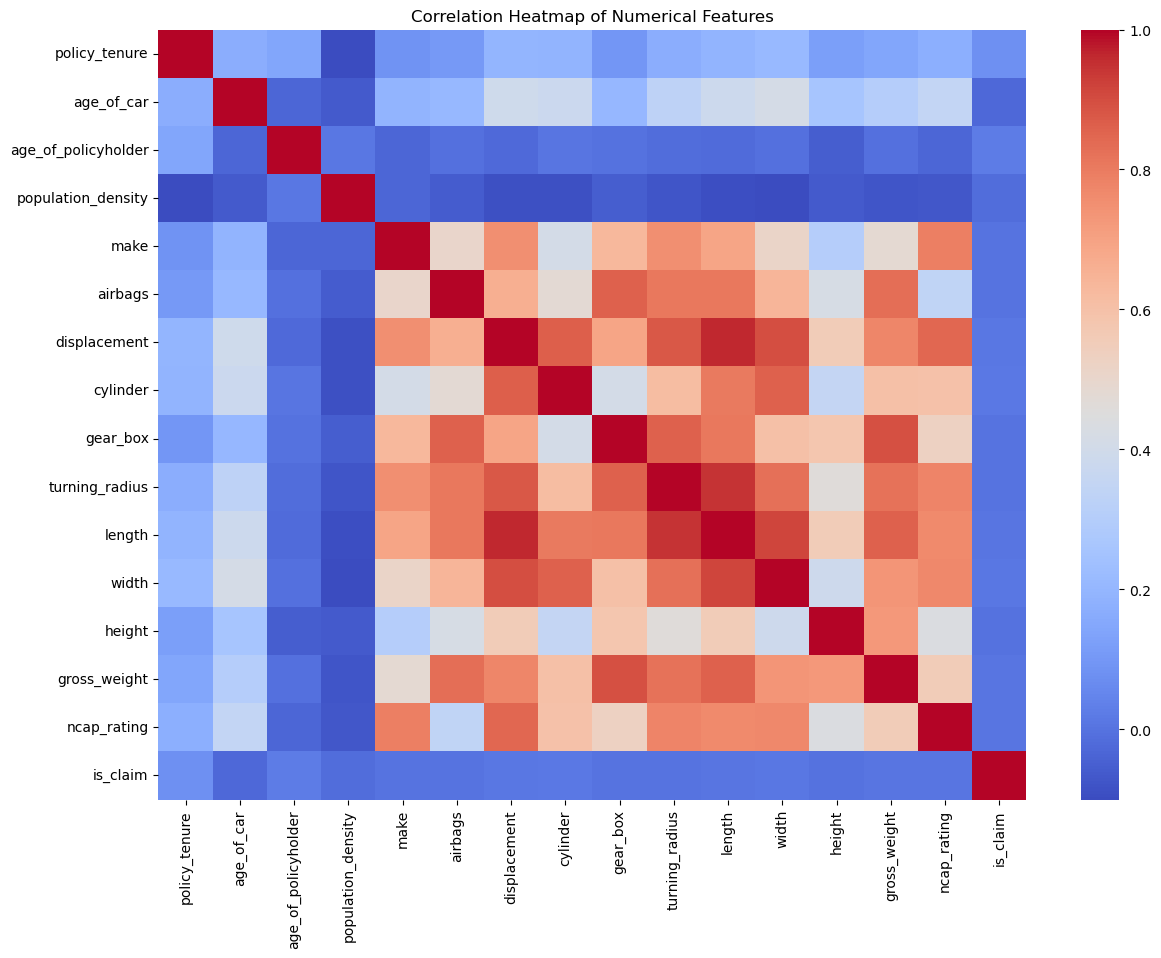

In [35]:
# Correlation matrix for numerical columns including target

corr_matrix = df_analysis[numerical_cols_analysis].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Observation

The correlation heatmap helps identify relationships among numerical variables. Highly correlated independent variables may need to be handled before logistic regression because multicollinearity can affect coefficient interpretation.

## 36. Correlation of Numerical Features with Target Variable

The correlation of numerical variables with `is_claim` is checked to understand which numerical features have stronger linear association with claim status.

In [36]:
# Correlation of numerical features with target variable

target_correlation = corr_matrix["is_claim"].sort_values(ascending=False)
target_correlation

is_claim               1.000000
policy_tenure          0.078747
age_of_policyholder    0.022435
cylinder               0.013434
width                  0.009947
displacement           0.007678
length                 0.006495
gross_weight           0.003894
ncap_rating            0.003800
airbags                0.002789
turning_radius         0.002724
make                  -0.000456
gear_box              -0.000635
height                -0.002024
population_density    -0.017808
age_of_car            -0.028172
Name: is_claim, dtype: float64

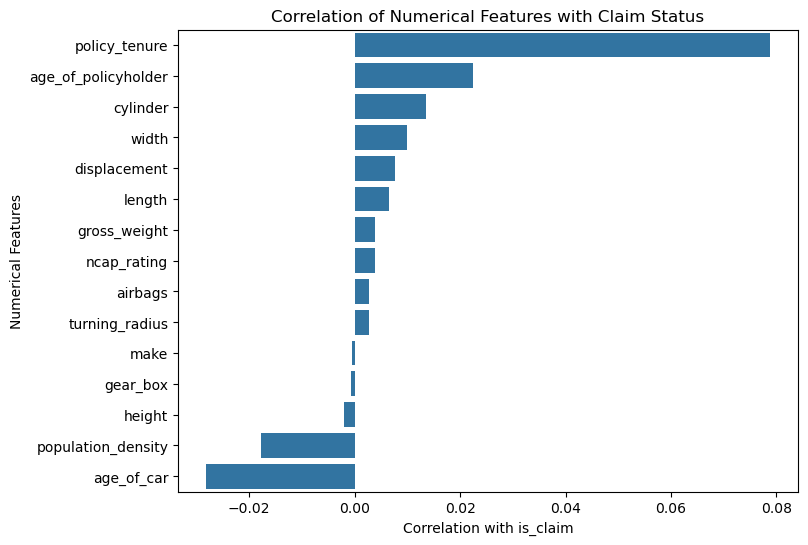

In [37]:
# Visualising correlation with target variable

target_corr_without_self = target_correlation.drop("is_claim")

plt.figure(figsize=(8, 6))
sns.barplot(x=target_corr_without_self.values, y=target_corr_without_self.index)
plt.title("Correlation of Numerical Features with Claim Status")
plt.xlabel("Correlation with is_claim")
plt.ylabel("Numerical Features")
plt.show()

### Observation

The correlation values show the direction and strength of linear relationship between numerical features and claim status. Since claim behaviour can be influenced by non-linear patterns as well, correlation alone should not be used for final feature selection.

## 37. Summary of Bivariate Analysis

Bivariate analysis helped compare numerical and categorical features against the target variable `is_claim`.

Key points observed:

- The dataset has an imbalanced target variable.
- Numerical features were compared between claim and no-claim groups using boxplots and mean comparison.
- Categorical features were analysed using claim rate tables and bar charts.
- Some categories show higher claim rates than the overall average claim rate.
- Correlation analysis helped identify relationships among numerical variables and with the target variable.
- Further preprocessing and feature engineering will be performed before model building.

## 38. Outlier Detection Using IQR Method

Outliers are extreme values that are very different from the majority of data points. In insurance datasets, outliers should not be removed blindly because extreme values may contain useful risk-related information.

The Interquartile Range method is used to detect possible outliers in numerical features.

In [38]:
# Detecting outliers using IQR method

outlier_summary = []

for col in numerical_features:
    Q1 = df_analysis[col].quantile(0.25)
    Q3 = df_analysis[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_analysis[(df_analysis[col] < lower_bound) | (df_analysis[col] > upper_bound)]
    
    outlier_summary.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outliers.shape[0],
        "Outlier_Percentage": round((outliers.shape[0] / df_analysis.shape[0]) * 100, 2)
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
outlier_summary_df.sort_values(by="Outlier_Percentage", ascending=False)

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
8,gear_box,5.000000,5.000000,14381,24.54
3,population_density,-25224.500000,58339.500000,3647,6.22
1,age_of_car,-0.115000,0.245000,269,0.46
2,age_of_policyholder,0.091346,0.822115,221,0.38
0,policy_tenure,-1.033032,2.282386,0,0.00
4,make,-2.000000,6.000000,0,0.00
5,airbags,-4.000000,12.000000,0,0.00
6,displacement,-249.500000,2538.500000,0,0.00
7,cylinder,1.500000,5.500000,0,0.00
9,turning_radius,4.000000,5.600000,0,0.00


### Observation

The IQR method identifies possible outliers in numerical features. Since this is insurance claim data, outliers may represent genuine high-risk or unusual policy/vehicle records. Therefore, outliers will not be removed directly. Instead, capping will be applied only where required to reduce the impact of extreme values while preserving the records.

## 39. Outlier Treatment Using Capping

Outlier capping is used instead of deleting records. Values below the lower bound are capped at the lower bound, and values above the upper bound are capped at the upper bound.

This approach keeps all policy records while reducing the influence of extreme numerical values.

In [39]:
# Creating a copy for cleaned data

df_cleaned = df_analysis.copy()

# Capping outliers using IQR method

for col in numerical_features:
    Q1 = df_cleaned[col].quantile(0.25)
    Q3 = df_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df_cleaned[col] = np.where(df_cleaned[col] < lower_bound, lower_bound, df_cleaned[col])
    df_cleaned[col] = np.where(df_cleaned[col] > upper_bound, upper_bound, df_cleaned[col])

df_cleaned.head()

,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,max_torque,max_power,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,0.515874,0.05,0.644231,C1,4990.0,1.0,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0
1,0.672619,0.02,0.375000,C2,27003.0,1.0,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0
2,0.841110,0.02,0.384615,C3,4076.0,1.0,A,M1,CNG,60Nm@3500rpm,40.36bhp@6000rpm,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0
3,0.900277,0.11,0.432692,C4,21622.0,1.0,C1,M2,Petrol,113Nm@4400rpm,88.50bhp@6000rpm,1.2 L K12N Dualjet,2.0,Yes,Yes,No,Yes,Yes,Drum,1197.0,4.0,Automatic,5.0,Electric,4.8,3995.0,1735.0,1515.0,1335.0,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2.0,0
4,0.596403,0.11,0.634615,C5,34738.0,2.0,A,M3,Petrol,91Nm@4250rpm,67.06bhp@5500rpm,1.0 SCe,2.0,No,No,No,No,Yes,Drum,999.0,3.0,Automatic,5.0,Electric,5.0,3731.0,1579.0,1490.0,1155.0,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2.0,0


### Observation

Outlier capping has been applied to numerical features. This helps reduce the effect of extreme values without removing any policy records from the dataset.

## 40. Feature Engineering

Feature engineering is performed to create new business-relevant variables from existing columns. These features may help the model capture claim-risk patterns more effectively.

The engineered features are based on policy tenure, vehicle age, policyholder age, vehicle safety features, vehicle size, and vehicle performance.

In [40]:
# Creating vehicle age group

df_cleaned["car_age_group"] = pd.cut(
    df_cleaned["age_of_car"],
    bins=[-0.01, 0.03, 0.07, 0.12, 1],
    labels=["New", "Moderately_Old", "Old", "Very_Old"]
)

# Creating policyholder age group

df_cleaned["policyholder_age_group"] = pd.cut(
    df_cleaned["age_of_policyholder"],
    bins=[0, 0.35, 0.45, 0.55, 1],
    labels=["Young", "Adult", "Middle_Aged", "Senior"]
)

df_cleaned[["age_of_car", "car_age_group", "age_of_policyholder", "policyholder_age_group"]].head()

,age_of_car,car_age_group,age_of_policyholder,policyholder_age_group
0,0.05,Moderately_Old,0.644231,Senior
1,0.02,New,0.375000,Adult
2,0.02,New,0.384615,Adult
3,0.11,Old,0.432692,Adult
4,0.11,Old,0.634615,Senior


### Observation

Two age-based features were created:

- `car_age_group` groups vehicles based on their age.
- `policyholder_age_group` groups policyholders into broad age categories.

These features make the analysis more interpretable from a business perspective.

## 41. Safety Score Feature

A safety score is created by combining multiple vehicle safety-related features. Vehicles with more safety features may have different claim-risk behaviour compared to vehicles with fewer safety features.

In [41]:
# Identifying Yes/No safety feature columns

safety_cols = [
    "is_esc",
    "is_adjustable_steering",
    "is_tpms",
    "is_parking_sensors",
    "is_parking_camera",
    "is_front_fog_lights",
    "is_rear_window_wiper",
    "is_rear_window_washer",
    "is_rear_window_defogger",
    "is_brake_assist",
    "is_power_door_locks",
    "is_central_locking",
    "is_power_steering",
    "is_driver_seat_height_adjustable",
    "is_day_night_rear_view_mirror",
    "is_ecw",
    "is_speed_alert"
]

# Creating safety score by counting Yes values
df_cleaned["safety_score"] = df_cleaned[safety_cols].apply(lambda row: sum(row == "Yes"), axis=1)

# Creating safety score group
df_cleaned["safety_score_group"] = pd.cut(
    df_cleaned["safety_score"],
    bins=[-1, 5, 10, 17],
    labels=["Low_Safety", "Medium_Safety", "High_Safety"]
)

df_cleaned[["safety_score", "safety_score_group"]].head()

,safety_score,safety_score_group
0,3,Low_Safety
1,3,Low_Safety
2,3,Low_Safety
3,14,High_Safety
4,7,Medium_Safety


### Observation

The `safety_score` feature represents the total number of available safety features in each vehicle. The `safety_score_group` feature segments vehicles into Low, Medium, and High safety groups.

## 42. Vehicle Size and Performance Features

Additional vehicle-related features are created using vehicle dimensions, engine power, and gross weight.

In [43]:
# Extracting numeric value from max_power and max_torque columns

df_cleaned["max_power_value"] = pd.to_numeric(
    df_cleaned["max_power"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

df_cleaned["max_torque_value"] = pd.to_numeric(
    df_cleaned["max_torque"].astype(str).str.extract(r"(\d+\.?\d*)")[0],
    errors="coerce"
)

# Ensuring gross_weight is numeric

df_cleaned["gross_weight"] = pd.to_numeric(df_cleaned["gross_weight"], errors="coerce")

# Filling any missing values created during conversion

df_cleaned["max_power_value"] = df_cleaned["max_power_value"].fillna(df_cleaned["max_power_value"].median())
df_cleaned["max_torque_value"] = df_cleaned["max_torque_value"].fillna(df_cleaned["max_torque_value"].median())
df_cleaned["gross_weight"] = df_cleaned["gross_weight"].fillna(df_cleaned["gross_weight"].median())

# Creating vehicle volume using length, width and height

df_cleaned["vehicle_volume"] = df_cleaned["length"] * df_cleaned["width"] * df_cleaned["height"]

# Creating power-to-weight ratio using extracted numeric power value

df_cleaned["power_to_weight_ratio"] = df_cleaned["max_power_value"] / df_cleaned["gross_weight"]

# Creating torque-to-weight ratio using extracted numeric torque value

df_cleaned["torque_to_weight_ratio"] = df_cleaned["max_torque_value"] / df_cleaned["gross_weight"]

# Displaying newly created features

df_cleaned[
    [
        "max_power",
        "max_power_value",
        "max_torque",
        "max_torque_value",
        "vehicle_volume",
        "power_to_weight_ratio",
        "torque_to_weight_ratio"
    ]
].head()

,max_power,max_power_value,max_torque,max_torque_value,vehicle_volume,power_to_weight_ratio,torque_to_weight_ratio
0,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0,7.698283e+09,0.034059,0.050633
1,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0,7.698283e+09,0.034059,0.050633
2,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0,7.698283e+09,0.034059,0.050633
3,88.50bhp@6000rpm,88.50,113Nm@4400rpm,113.0,1.050096e+10,0.066292,0.084644
4,67.06bhp@5500rpm,67.06,91Nm@4250rpm,91.0,8.777961e+09,0.058061,0.078788


### Observation

The `max_power` and `max_torque` columns were originally stored as text values because they contained units such as bhp, rpm, and Nm. Numeric values were extracted from these columns to create model-friendly features.

The following vehicle-related features were created:

- `max_power_value` captures the numeric engine power value.
- `max_torque_value` captures the numeric torque value.
- `vehicle_volume` captures the approximate size of the vehicle.
- `power_to_weight_ratio` captures vehicle performance relative to weight.
- `torque_to_weight_ratio` captures torque capacity relative to vehicle weight.

These engineered features may help explain claim-risk differences across vehicle types.

## 43. Checking Engineered Features

The newly engineered features are inspected to confirm that they were created correctly.

In [44]:
# Checking newly engineered columns

engineered_cols = [
    "car_age_group",
    "policyholder_age_group",
    "safety_score",
    "safety_score_group",
    "vehicle_volume",
    "power_to_weight_ratio",
    "torque_to_weight_ratio"
]

df_cleaned[engineered_cols].head()

,car_age_group,policyholder_age_group,safety_score,safety_score_group,vehicle_volume,power_to_weight_ratio,torque_to_weight_ratio
0,Moderately_Old,Senior,3,Low_Safety,7.698283e+09,0.034059,0.050633
1,New,Adult,3,Low_Safety,7.698283e+09,0.034059,0.050633
2,New,Adult,3,Low_Safety,7.698283e+09,0.034059,0.050633
3,Old,Adult,14,High_Safety,1.050096e+10,0.066292,0.084644
4,Old,Senior,7,Medium_Safety,8.777961e+09,0.058061,0.078788


In [45]:
# Checking shape after feature engineering

df_cleaned.shape

(58592, 52)

### Observation

The engineered features have been successfully added to the dataset. These features will improve business interpretability and may help the model capture additional claim-risk patterns.

## 44. Final Check After Feature Engineering

After creating new features, the dataset is checked again for missing values, data types, and shape to ensure that feature engineering did not introduce any issues.

In [46]:
# Checking shape after feature engineering

df_cleaned.shape

(58592, 52)

In [47]:
# Checking missing values after feature engineering

df_cleaned.isnull().sum().sort_values(ascending=False).head(20)

policy_tenure                       0
age_of_car                          0
gross_weight                        0
is_front_fog_lights                 0
is_rear_window_wiper                0
is_rear_window_washer               0
is_rear_window_defogger             0
is_brake_assist                     0
is_power_door_locks                 0
is_central_locking                  0
is_power_steering                   0
is_driver_seat_height_adjustable    0
is_day_night_rear_view_mirror       0
is_ecw                              0
is_speed_alert                      0
ncap_rating                         0
is_claim                            0
car_age_group                       0
policyholder_age_group              0
safety_score                        0
dtype: int64

In [48]:
# Checking data types after feature engineering

df_cleaned.dtypes

policy_tenure                        float64
age_of_car                           float64
age_of_policyholder                  float64
area_cluster                          object
population_density                   float64
make                                 float64
segment                               object
model                                 object
fuel_type                             object
max_torque                            object
max_power                             object
engine_type                           object
airbags                              float64
is_esc                                object
is_adjustable_steering                object
is_tpms                               object
is_parking_sensors                    object
is_parking_camera                     object
rear_brakes_type                      object
displacement                         float64
cylinder                             float64
transmission_type                     object
gear_box  

### Observation

After feature engineering, the dataset was checked again. This ensures that newly created features did not introduce missing values or datatype issues.

## 45. Skewness Treatment

Skewness was checked earlier during numerical analysis. In this step, highly skewed non-negative numerical features are transformed using log transformation.

Log transformation helps reduce extreme skewness and makes numerical distributions more stable for modelling.

In [49]:
# Updating numerical columns after feature engineering

numeric_cols_cleaned = df_cleaned.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Removing target variable from numerical feature list
numeric_features_cleaned = [col for col in numeric_cols_cleaned if col != "is_claim"]

# Checking skewness after feature engineering
skewness_after_fe = pd.DataFrame({
    "Feature": numeric_features_cleaned,
    "Skewness": [df_cleaned[col].skew() for col in numeric_features_cleaned]
}).sort_values(by="Skewness", ascending=False)

skewness_after_fe

,Feature,Skewness
4,make,1.197457
3,population_density,1.162328
12,height,1.035498
5,airbags,0.905946
20,torque_to_weight_ratio,0.697556
18,max_torque_value,0.671799
1,age_of_car,0.651123
2,age_of_policyholder,0.615271
13,gross_weight,0.546949
9,turning_radius,0.420983


In [50]:
# Selecting highly skewed non-negative numerical features for log transformation

skewed_cols = []

for col in numeric_features_cleaned:
    if df_cleaned[col].nunique() > 10:
        if abs(df_cleaned[col].skew()) > 1 and df_cleaned[col].min() >= 0:
            skewed_cols.append(col)

print("Highly skewed columns selected for log transformation:")
print(skewed_cols)

Highly skewed columns selected for log transformation:
['population_density', 'height']


In [51]:
# Applying log transformation to selected skewed columns

for col in skewed_cols:
    df_cleaned["log_" + col] = np.log1p(df_cleaned[col])

# Checking newly created log-transformed columns
log_cols = ["log_" + col for col in skewed_cols]
df_cleaned[log_cols].head()

,log_population_density,log_height
0,8.515392,7.297091
1,10.203740,7.297091
2,8.313117,7.297091
3,9.981513,7.323831
4,10.455618,7.307202


### Observation

Highly skewed non-negative numerical features were identified and log-transformed where required. These transformed features can help reduce the impact of skewness during modelling.

## 46. Preparing Dataset for Encoding

Before encoding categorical variables, columns containing text-based engine information are handled. The original `max_power` and `max_torque` columns contain units and text, so numeric values extracted earlier will be used instead.

In [53]:
# Creating modelling base dataset

df_model_base = df_cleaned.copy()

# Dropping original text-based power and torque columns
df_model_base = df_model_base.drop(columns=["max_power", "max_torque"], errors="ignore")

# Adding policy_id back for traceability
df_model_base.insert(0, "policy_id", df["policy_id"])

df_model_base.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,engine_type,airbags,is_esc,is_adjustable_steering,is_tpms,is_parking_sensors,is_parking_camera,rear_brakes_type,displacement,cylinder,transmission_type,gear_box,steering_type,turning_radius,length,width,height,gross_weight,is_front_fog_lights,is_rear_window_wiper,is_rear_window_washer,is_rear_window_defogger,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim,car_age_group,policyholder_age_group,safety_score,safety_score_group,vehicle_volume,max_power_value,max_torque_value,power_to_weight_ratio,torque_to_weight_ratio,log_population_density,log_height
0,ID00001,0.515874,0.05,0.644231,C1,4990.0,1.0,A,M1,CNG,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0,Moderately_Old,Senior,3,Low_Safety,7.698283e+09,40.36,60.0,0.034059,0.050633,8.515392,7.297091
1,ID00002,0.672619,0.02,0.375000,C2,27003.0,1.0,A,M1,CNG,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0,New,Adult,3,Low_Safety,7.698283e+09,40.36,60.0,0.034059,0.050633,10.203740,7.297091
2,ID00003,0.841110,0.02,0.384615,C3,4076.0,1.0,A,M1,CNG,F8D Petrol Engine,2.0,No,No,No,Yes,No,Drum,796.0,3.0,Manual,5.0,Power,4.6,3445.0,1515.0,1475.0,1185.0,No,No,No,No,No,No,No,Yes,No,No,No,Yes,0.0,0,New,Adult,3,Low_Safety,7.698283e+09,40.36,60.0,0.034059,0.050633,8.313117,7.297091
3,ID00004,0.900277,0.11,0.432692,C4,21622.0,1.0,C1,M2,Petrol,1.2 L K12N Dualjet,2.0,Yes,Yes,No,Yes,Yes,Drum,1197.0,4.0,Automatic,5.0,Electric,4.8,3995.0,1735.0,1515.0,1335.0,Yes,No,No,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2.0,0,Old,Adult,14,High_Safety,1.050096e+10,88.50,113.0,0.066292,0.084644,9.981513,7.323831
4,ID00005,0.596403,0.11,0.634615,C5,34738.0,2.0,A,M3,Petrol,1.0 SCe,2.0,No,No,No,No,Yes,Drum,999.0,3.0,Automatic,5.0,Electric,5.0,3731.0,1579.0,1490.0,1155.0,No,No,No,No,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2.0,0,Old,Senior,7,Medium_Safety,8.777961e+09,67.06,91.0,0.058061,0.078788,10.455618,7.307202


### Observation

The original text-based `max_power` and `max_torque` columns were removed because their numeric values have already been extracted into `max_power_value` and `max_torque_value`. The `policy_id` column was added back only for record identification and will not be used as a modelling feature.

## 47. Categorical Encoding

Machine learning models require numerical input. Therefore, categorical variables are converted into numerical format using one-hot encoding.

The `policy_id` column is not encoded because it is only an identifier.

In [54]:
# Separating identifier, target, and input features

id_col = df_model_base[["policy_id"]]
target = df_model_base[["is_claim"]]

X = df_model_base.drop(columns=["policy_id", "is_claim"], errors="ignore")

# Checking categorical columns before encoding
categorical_cols_final = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Categorical columns to be encoded:")
print(categorical_cols_final)

Categorical columns to be encoded:
['area_cluster', 'segment', 'model', 'fuel_type', 'engine_type', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'transmission_type', 'steering_type', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'car_age_group', 'policyholder_age_group', 'safety_score_group']


In [55]:
# Applying one-hot encoding

X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

# Combining policy_id, encoded features, and target variable
cleaned_dataset = pd.concat(
    [
        id_col.reset_index(drop=True),
        X_encoded.reset_index(drop=True),
        target.reset_index(drop=True)
    ],
    axis=1
)

cleaned_dataset.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,safety_score,vehicle_volume,max_power_value,max_torque_value,power_to_weight_ratio,torque_to_weight_ratio,log_population_density,log_height,area_cluster_C10,area_cluster_C11,area_cluster_C12,area_cluster_C13,area_cluster_C14,area_cluster_C15,area_cluster_C16,area_cluster_C17,area_cluster_C18,area_cluster_C19,area_cluster_C2,area_cluster_C20,area_cluster_C21,area_cluster_C22,area_cluster_C3,area_cluster_C4,area_cluster_C5,area_cluster_C6,area_cluster_C7,area_cluster_C8,area_cluster_C9,segment_B1,segment_B2,segment_C1,segment_C2,segment_Utility,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9,fuel_type_Diesel,fuel_type_Petrol,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 L U2 CRDi,engine_type_1.5 Turbocharged Revotorq,engine_type_1.5 Turbocharged Revotron,engine_type_F8D Petrol Engine,engine_type_G12B,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,is_esc_Yes,is_adjustable_steering_Yes,is_tpms_Yes,is_parking_sensors_Yes,is_parking_camera_Yes,rear_brakes_type_Drum,transmission_type_Manual,steering_type_Manual,steering_type_Power,is_front_fog_lights_Yes,is_rear_window_wiper_Yes,is_rear_window_washer_Yes,is_rear_window_defogger_Yes,is_brake_assist_Yes,is_power_door_locks_Yes,is_central_locking_Yes,is_power_steering_Yes,is_driver_seat_height_adjustable_Yes,is_day_night_rear_view_mirror_Yes,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety,is_claim
0,ID00001,0.515874,0.05,0.644231,4990.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.515392,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,0
1,ID00002,0.672619,0.02,0.375000,27003.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,10.203740,7.297091,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
2,ID00003,0.841110,0.02,0.384615,4076.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.313117,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
3,ID00004,0.900277,0.11,0.432692,21622.0,1.0,2.0,1197.0,4.0,5.0,4.8,3995.0,1735.0,1515.0,1335.0,2.0,14,1.050096e+10,88.50,113.0,0.066292,0.084644,9.981513,7.323831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,0,1,0
4,ID00005,0.596403,0.11,0.634615,34738.0,2.0,2.0,999.0,3.0,5.0,5.0,3731.0,1579.0,1490.0,1155.0,2.0,7,8.777961e+09,67.06,91.0,0.058061,0.078788,10.455618,7.307202,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,0,1,0,0,0,1,1,0,0


In [56]:
# Checking shape after encoding

cleaned_dataset.shape

(58592, 102)

In [57]:
# Checking final dataset data types

cleaned_dataset.dtypes.value_counts()

int64      79
float64    22
object      1
Name: count, dtype: int64

### Observation

Categorical variables were encoded using one-hot encoding. The final cleaned dataset now contains numerical model-ready features along with `policy_id` for identification and `is_claim` as the target variable.

## 48. Variance Inflation Factor Analysis

Variance Inflation Factor is used to check multicollinearity among independent variables. High VIF values indicate that a feature is highly correlated with other features.

For logistic regression, checking multicollinearity is important because highly correlated features can make coefficient interpretation unstable.

In [60]:
# Importing VIF and scaling libraries

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

In [61]:
# Importing required libraries for VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler

# Preparing data for VIF calculation

X_vif = cleaned_dataset.drop(columns=["policy_id", "is_claim"], errors="ignore")

# Removing constant columns if any
X_vif = X_vif.loc[:, X_vif.nunique() > 1]

# Taking a sample to make VIF calculation faster
X_vif_sample = X_vif.sample(n=min(5000, len(X_vif)), random_state=42)

# Scaling features before VIF
scaler = StandardScaler()

X_vif_scaled = pd.DataFrame(
    scaler.fit_transform(X_vif_sample),
    columns=X_vif_sample.columns
)

X_vif_scaled.head()

,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,turning_radius,length,width,height,gross_weight,ncap_rating,safety_score,vehicle_volume,max_power_value,max_torque_value,power_to_weight_ratio,torque_to_weight_ratio,log_population_density,log_height,area_cluster_C10,area_cluster_C11,area_cluster_C12,area_cluster_C13,area_cluster_C14,area_cluster_C15,area_cluster_C16,area_cluster_C17,area_cluster_C18,area_cluster_C19,area_cluster_C2,area_cluster_C20,area_cluster_C21,area_cluster_C22,area_cluster_C3,area_cluster_C4,area_cluster_C5,area_cluster_C6,area_cluster_C7,area_cluster_C8,area_cluster_C9,segment_B1,segment_B2,segment_C1,segment_C2,segment_Utility,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9,fuel_type_Diesel,fuel_type_Petrol,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 L U2 CRDi,engine_type_1.5 Turbocharged Revotorq,engine_type_1.5 Turbocharged Revotron,engine_type_F8D Petrol Engine,engine_type_G12B,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,is_esc_Yes,is_adjustable_steering_Yes,is_tpms_Yes,is_parking_sensors_Yes,is_parking_camera_Yes,rear_brakes_type_Drum,transmission_type_Manual,steering_type_Manual,steering_type_Power,is_front_fog_lights_Yes,is_rear_window_wiper_Yes,is_rear_window_washer_Yes,is_rear_window_defogger_Yes,is_brake_assist_Yes,is_power_door_locks_Yes,is_central_locking_Yes,is_power_steering_Yes,is_driver_seat_height_adjustable_Yes,is_day_night_rear_view_mirror_Yes,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety
0,-0.780675,-0.359771,0.332943,-0.904556,2.801571,-0.640186,1.229540,0.754237,0.183514,0.438462,0.186109,-0.658239,-1.569563,1.597800,0.427037,0.027450,0.658635,0.860227,2.341173,2.353937,-1.169877,-0.659793,-0.243561,-0.144308,-0.162088,-0.241249,-0.257978,-0.120019,-0.082744,-0.090927,-0.070888,-0.119159,-0.369974,-0.037443,-0.08516,-0.054855,2.888909,-0.114766,-0.364714,-0.124236,-0.203059,-0.558870,-0.222572,-0.258419,-0.675926,3.986464,-0.577966,-0.141393,-0.141393,-0.073684,-0.128323,-0.199292,-0.577966,-0.167214,-0.554555,-0.232299,-0.258419,5.059224,1.47397,-0.727681,-0.232299,-0.128323,-0.577966,-0.167214,-0.073684,-0.587204,-0.141393,-0.554555,-0.258419,5.059224,-0.691044,0.786541,-0.577966,0.199292,1.227300,0.577966,0.743502,-0.141393,-1.162684,0.832582,-0.657149,-0.657149,1.331022,-1.124497,0.617426,0.617426,0.141393,0.823318,1.281681,0.617426,0.073684,1.873117,-0.539743,-0.489979,-0.649047,1.634341,-0.556713,-0.392345,0.832582
1,-1.172435,-0.359771,-0.525680,-0.594947,-0.686441,-0.640186,0.108900,0.754237,-0.250941,-0.038225,0.541824,-0.290236,-0.250539,0.165438,0.234105,0.051590,0.321566,-0.315343,0.636531,-0.230528,-0.349341,-0.273993,-0.243561,-0.144308,-0.162088,-0.241249,-0.257978,-0.120019,-0.082744,-0.090927,-0.070888,-0.119159,-0.369974,-0.037443,-0.08516,-0.054855,-0.346151,-0.114766,-0.364714,-0.124236,-0.203059,1.789324,-0.222572,-0.258419,1.479451,-0.250849,-0.577966,-0.141393,-0.141393,-0.073684,-0.128323,-0.199292,-0.577966,-0.167214,1.803247,-0.232299,-0.258419,-0.197659,-0.67844,1.374228,-0.232299,-0.128323,-0.577966,-0.167214,-0.073684,-0.587204,-0.141393,1.803247,-0.258419,-0.197659,-0.691044,0.786541,-0.577966,0.199292,-0.814797,0.577966,0.743502,-0.141393,-1.162684,0.832582,-0.657149,-0.657149,-0.751303,0.889287,0.617426,0.617426,0.141393,0.823318,1.281681,0.617426,0.073684,1.873117,-0.539743,-0.489979,1.540720,-0.611867,-0.556713,-0.392345,0.832582
2,-0.954865,-0.715839,-0.837907,-0.904556,1.057565,1.517503,1.210925,0.754237,1.486879,1.407726,1.030934,1.042191,1.537576,0.881619,1.198769,1.396333,1.217185,1.535841,0.615399,1.254450,-1.169877,1.064215,-0.243561,-0.144308,-0.162088,-0.241249,-0.257978,-0.120019,-

In [63]:
# Calculating VIF values

vif_data = pd.DataFrame()
vif_data["Feature"] = X_vif_scaled.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif_scaled.values, i)
    for i in range(X_vif_scaled.shape[1])
]

# Sorting VIF values
vif_data = vif_data.sort_values(by="VIF", ascending=False)

vif_data.head(30)

,Feature,VIF
49,model_M11,inf
59,fuel_type_Petrol,inf
68,engine_type_K10C,inf
67,engine_type_K Series Dual jet,inf
66,engine_type_G12B,inf
65,engine_type_F8D Petrol Engine,inf
64,engine_type_1.5 Turbocharged Revotron,inf
63,engine_type_1.5 Turbocharged Revotorq,inf
62,engine_type_1.5 L U2 CRDi,inf
61,engine_type_1.2 L K12N Dualjet,inf


### Observation

VIF analysis helps identify features with possible multicollinearity. Features with very high VIF values may be reviewed before model building. However, feature removal should be done carefully because some engineered features may still have business value.

## 49. Review of High VIF Features

The VIF output is reviewed to identify features with high multicollinearity. Very high VIF values indicate that some features carry overlapping information.

However, features are not removed blindly because some correlated variables may still have business meaning. Final feature selection can be further refined during model building using validation metrics and regularization.

In [64]:
# Displaying high VIF features

high_vif_features = vif_data[vif_data["VIF"] > 10]

print("Number of features with VIF greater than 10:", high_vif_features.shape[0])
high_vif_features.head(30)

Number of features with VIF greater than 10: 93


,Feature,VIF
49,model_M11,inf
59,fuel_type_Petrol,inf
68,engine_type_K10C,inf
67,engine_type_K Series Dual jet,inf
66,engine_type_G12B,inf
65,engine_type_F8D Petrol Engine,inf
64,engine_type_1.5 Turbocharged Revotron,inf
63,engine_type_1.5 Turbocharged Revotorq,inf
62,engine_type_1.5 L U2 CRDi,inf
61,engine_type_1.2 L K12N Dualjet,inf


### Observation

Some features may show high VIF values due to correlations between vehicle specifications, safety features, and engineered variables. These features will be reviewed during model building. Since the final model will be evaluated using validation metrics, features will not be removed blindly at this stage.

## 50. Final Cleaned Dataset

The final cleaned dataset contains:

- Standardised categorical labels
- Outlier-capped numerical features
- Engineered business-relevant features
- Encoded categorical variables
- Policy identifier for traceability
- Target variable `is_claim`

This dataset is ready to be exported and used for model building in Stage 2.

In [65]:
# Final cleaned dataset preview

cleaned_dataset.head()

,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,safety_score,vehicle_volume,max_power_value,max_torque_value,power_to_weight_ratio,torque_to_weight_ratio,log_population_density,log_height,area_cluster_C10,area_cluster_C11,area_cluster_C12,area_cluster_C13,area_cluster_C14,area_cluster_C15,area_cluster_C16,area_cluster_C17,area_cluster_C18,area_cluster_C19,area_cluster_C2,area_cluster_C20,area_cluster_C21,area_cluster_C22,area_cluster_C3,area_cluster_C4,area_cluster_C5,area_cluster_C6,area_cluster_C7,area_cluster_C8,area_cluster_C9,segment_B1,segment_B2,segment_C1,segment_C2,segment_Utility,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9,fuel_type_Diesel,fuel_type_Petrol,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 L U2 CRDi,engine_type_1.5 Turbocharged Revotorq,engine_type_1.5 Turbocharged Revotron,engine_type_F8D Petrol Engine,engine_type_G12B,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,is_esc_Yes,is_adjustable_steering_Yes,is_tpms_Yes,is_parking_sensors_Yes,is_parking_camera_Yes,rear_brakes_type_Drum,transmission_type_Manual,steering_type_Manual,steering_type_Power,is_front_fog_lights_Yes,is_rear_window_wiper_Yes,is_rear_window_washer_Yes,is_rear_window_defogger_Yes,is_brake_assist_Yes,is_power_door_locks_Yes,is_central_locking_Yes,is_power_steering_Yes,is_driver_seat_height_adjustable_Yes,is_day_night_rear_view_mirror_Yes,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety,is_claim
0,ID00001,0.515874,0.05,0.644231,4990.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.515392,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,0
1,ID00002,0.672619,0.02,0.375000,27003.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,10.203740,7.297091,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
2,ID00003,0.841110,0.02,0.384615,4076.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.313117,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
3,ID00004,0.900277,0.11,0.432692,21622.0,1.0,2.0,1197.0,4.0,5.0,4.8,3995.0,1735.0,1515.0,1335.0,2.0,14,1.050096e+10,88.50,113.0,0.066292,0.084644,9.981513,7.323831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,0,1,0
4,ID00005,0.596403,0.11,0.634615,34738.0,2.0,2.0,999.0,3.0,5.0,5.0,3731.0,1579.0,1490.0,1155.0,2.0,7,8.777961e+09,67.06,91.0,0.058061,0.078788,10.455618,7.307202,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,0,1,0,0,0,1,1,0,0


In [66]:
# Final cleaned dataset shape

cleaned_dataset.shape

(58592, 102)

In [67]:
# Final missing value check

cleaned_dataset.isnull().sum().sum()

np.int64(0)

In [68]:
# Final duplicate check

cleaned_dataset.duplicated().sum()

np.int64(0)

### Observation

The final cleaned dataset has been checked for missing values and duplicate records. The dataset is now ready for export as `cleaned_dataset.csv`.

## 51. Export Cleaned Dataset

The cleaned, analysis-ready dataset is exported as `cleaned_dataset.csv`. This file will be used as the input dataset for Stage 2 model building and validation.

In [69]:
# Exporting cleaned dataset

cleaned_dataset.to_csv("cleaned_dataset.csv", index=False)

print("cleaned_dataset.csv has been exported successfully.")

cleaned_dataset.csv has been exported successfully.


In [70]:
# Reading the exported file again to confirm successful export

test_cleaned = pd.read_csv("cleaned_dataset.csv")

print("Shape of exported cleaned dataset:", test_cleaned.shape)
test_cleaned.head()

Shape of exported cleaned dataset: (58592, 102)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,population_density,make,airbags,displacement,cylinder,gear_box,turning_radius,length,width,height,gross_weight,ncap_rating,safety_score,vehicle_volume,max_power_value,max_torque_value,power_to_weight_ratio,torque_to_weight_ratio,log_population_density,log_height,area_cluster_C10,area_cluster_C11,area_cluster_C12,area_cluster_C13,area_cluster_C14,area_cluster_C15,area_cluster_C16,area_cluster_C17,area_cluster_C18,area_cluster_C19,area_cluster_C2,area_cluster_C20,area_cluster_C21,area_cluster_C22,area_cluster_C3,area_cluster_C4,area_cluster_C5,area_cluster_C6,area_cluster_C7,area_cluster_C8,area_cluster_C9,segment_B1,segment_B2,segment_C1,segment_C2,segment_Utility,model_M10,model_M11,model_M2,model_M3,model_M4,model_M5,model_M6,model_M7,model_M8,model_M9,fuel_type_Diesel,fuel_type_Petrol,engine_type_1.2 L K Series Engine,engine_type_1.2 L K12N Dualjet,engine_type_1.5 L U2 CRDi,engine_type_1.5 Turbocharged Revotorq,engine_type_1.5 Turbocharged Revotron,engine_type_F8D Petrol Engine,engine_type_G12B,engine_type_K Series Dual jet,engine_type_K10C,engine_type_i-DTEC,is_esc_Yes,is_adjustable_steering_Yes,is_tpms_Yes,is_parking_sensors_Yes,is_parking_camera_Yes,rear_brakes_type_Drum,transmission_type_Manual,steering_type_Manual,steering_type_Power,is_front_fog_lights_Yes,is_rear_window_wiper_Yes,is_rear_window_washer_Yes,is_rear_window_defogger_Yes,is_brake_assist_Yes,is_power_door_locks_Yes,is_central_locking_Yes,is_power_steering_Yes,is_driver_seat_height_adjustable_Yes,is_day_night_rear_view_mirror_Yes,is_ecw_Yes,is_speed_alert_Yes,car_age_group_Moderately_Old,car_age_group_Old,car_age_group_Very_Old,policyholder_age_group_Adult,policyholder_age_group_Middle_Aged,policyholder_age_group_Senior,safety_score_group_Medium_Safety,safety_score_group_High_Safety,is_claim
0,ID00001,0.515874,0.05,0.644231,4990.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.515392,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,0,0,1,0,0,0
1,ID00002,0.672619,0.02,0.375000,27003.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,10.203740,7.297091,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
2,ID00003,0.841110,0.02,0.384615,4076.0,1.0,2.0,796.0,3.0,5.0,4.6,3445.0,1515.0,1475.0,1185.0,0.0,3,7.698283e+09,40.36,60.0,0.034059,0.050633,8.313117,7.297091,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,0
3,ID00004,0.900277,0.11,0.432692,21622.0,1.0,2.0,1197.0,4.0,5.0,4.8,3995.0,1735.0,1515.0,1335.0,2.0,14,1.050096e+10,88.50,113.0,0.066292,0.084644,9.981513,7.323831,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,1,1,0,1,1,1,0,0,0,1,0,0,1,1,1,1,1,1,1,1,1,0,1,0,1,0,0,0,1,0
4,ID00005,0.596403,0.11,0.634615,34738.0,2.0,2.0,999.0,3.0,5.0,5.0,3731.0,1579.0,1490.0,1155.0,2.0,7,8.777961e+09,67.06,91.0,0.058061,0.078788,10.455618,7.307202,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,0,1,0,0,0,1,1,0,0


## 52. Stage 1 Summary

Stage 1 of the capstone project has been completed.

The following tasks were performed:

- Business problem and analytical objective were defined.
- Dataset was loaded and inspected.
- Missing values and duplicate records were checked.
- Target variable distribution was analysed.
- Categorical labels were standardised.
- Numerical and categorical features were analysed using EDA.
- Bivariate analysis was performed against the target variable `is_claim`.
- Outliers were detected and capped using the IQR method.
- Skewness was checked and treated where required.
- Business-relevant features were engineered.
- Categorical variables were encoded using one-hot encoding.
- VIF analysis was performed to check multicollinearity.
- The final cleaned dataset was exported as `cleaned_dataset.csv`.

The cleaned dataset will now be used for Stage 2: Model Building and Validation.